#Effect of IGM in the spectrum

BAGPIPES: Generating IGM absorption table.
Bagpipes: Latex distribution not found, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


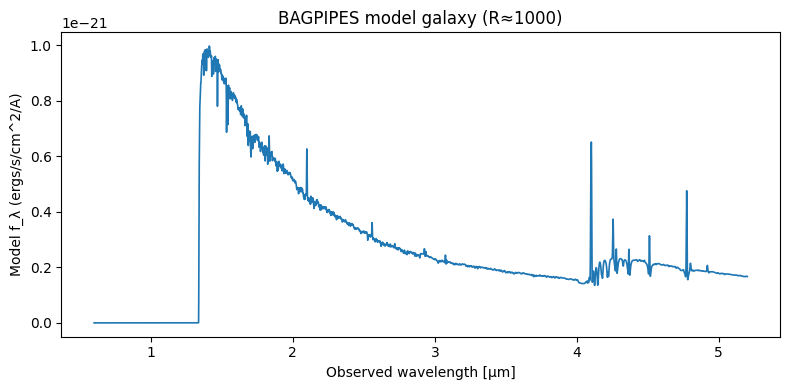

In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter1d
import bagpipes as pipes
import matplotlib.pyplot as plt

# -----------------------------
# 1) Choose an observed grid ~NIRSpec PRISM range, constant-R sampling
# -----------------------------
lam_min, lam_max = 0.60e4, 5.20e4     # Å (0.6–5.2 μm), NIRSpec PRISM coverage (R~100)
R_target = 1000.0

# Pick ~3 pixels per FWHM so we oversample (nice & stable)
# For constant R, spacing in lnλ should be constant. If FWHM/λ = 1/R, then pixel step d(lnλ) ~ (1/R)/3
dlnlam = (1.0/R_target)/3.0
ln_grid = np.arange(np.log(lam_min), np.log(lam_max)+dlnlam, dlnlam)
lam_obs = np.exp(ln_grid)             # Å, observed-frame grid

# -----------------------------
# 2) Define the BAGPIPES model (spectrum only)
# -----------------------------
# Example: z~14, blue UV slope, little dust, low Z, some LyC escape (no fitting here)
exp = {}
exp["age"] = 0.3         # Gyr  (young; adjust as you like)
exp["tau"] = 0.3        # Gyr
exp["massformed"] = 8.8   # log10(M*/Msun) — arbitrary for “a look”; scale as needed
exp["metallicity"] = 0.1  # Z/Z_sun (very metal-poor)

dust = {}
dust["type"] = "Calzetti"
dust["Av"] = 0.25
dust["eta"] = 3.0         # extra attenuation for very young stars

neb = {}
neb["logU"] = -2.5
neb["f_esc"] = 0.7        # high LyC escape to mute UV lines/continuum nebular

model_components = {}
model_components["redshift"] = 10
model_components["t_bc"] = 0.01       # Gyr birth-cloud lifetime
model_components["veldisp"] = 80.0    # km/s (stellar σ; small)
model_components["exponential"] = exp
model_components["dust"] = dust
model_components["nebular"] = neb

# Build the model ON YOUR grid (no photometry needed)
model = pipes.model_galaxy(model_components, spec_wavs=lam_obs)

# Get the raw model spectrum on that grid (in f_lambda; same units as BAGPIPES defaults)
# The plotting helper would also work (model.plot()), but we want arrays:
lam_model = lam_obs.copy()
#flux_model = model.spectrum["spec"]   # BAGPIPES fills this when spec_wavs is provided

#lam_model = lam_obs.copy()                 # Å (your log-λ grid)
#flux_model = np.asarray(model.spectrum)    # <-- it's a 1D array, not a dict
#flux_R100  = gaussian_filter1d(flux_model, sigma_pix, mode="nearest")
spec = np.array(model.spectrum)
lam_model = spec[:, 0]      # Å
flux_model = spec[:, 1]     # f_lambda

# -----------------------------
# 3) Convolve to constant resolving power R≈100
# -----------------------------
# For a Gaussian LSF: FWHM/λ = 1/R  => σ_lnλ = (1/R)/2.355 (constant on lnλ grid)
sigma_ln = (1.0/R_target)/2.355
sigma_pix = sigma_ln / dlnlam         # convert to pixels on our lnλ grid
flux_R100 = gaussian_filter1d(flux_model, sigma_pix, mode="nearest")

# -----------------------------
# 4) Plot or save the R~100 model
# -----------------------------
plt.figure(figsize=(8,4))
plt.plot(lam_model/1e4, flux_R100, lw=1.2)
plt.xlabel("Observed wavelength [μm]")
plt.ylabel("Model f_λ (ergs/s/cm^2/A)")
plt.title("BAGPIPES model galaxy (R≈1000)")
plt.tight_layout()
plt.show()

# If you want the arrays:
# lam_model (Å), flux_R100 (same units)

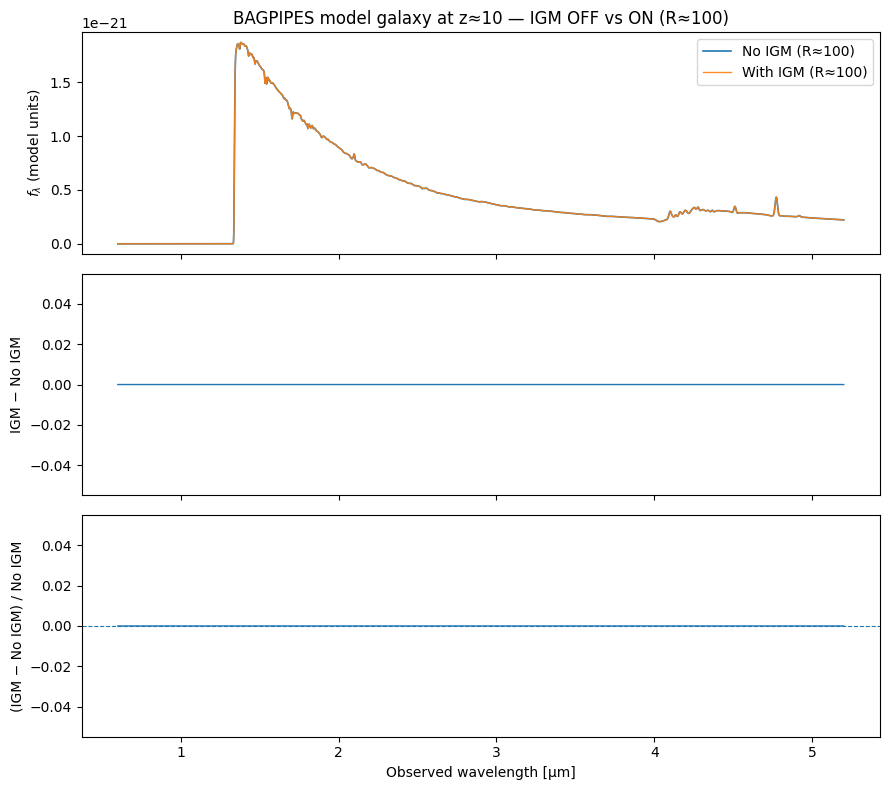

In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter1d
import bagpipes as pipes
import matplotlib.pyplot as plt

# -----------------------------
# 1) Observed-frame grid: NIRSpec PRISM range, constant-R sampling
# -----------------------------
lam_min, lam_max = 0.60e4, 5.20e4   # Å  (0.6–5.2 μm)
R_target = 1000.0                    # PRISM is ~100; set 1000 if you truly want R~1000 later

# Constant-R grid: uniform in ln(lambda). ~3 px per FWHM for numerical stability
dlnlam = (1.0 / R_target) / 3.0
ln_grid = np.arange(np.log(lam_min), np.log(lam_max) + dlnlam, dlnlam)
lam_obs = np.exp(ln_grid)  # Å

# -----------------------------
# 2) Define a BAGPIPES galaxy model (spectrum only)
# -----------------------------
exp = dict(age=0.3, tau=0.3, massformed=9, metallicity=0.01)  # Gyr, Gyr, log10(M*), Z/Zsun
dust = dict(type="Calzetti", Av=0.25, eta=3.0)
neb  = dict(logU=-2.5, f_esc=0.7)

base_components = {
    "redshift": 10.0,
    "t_bc": 0.01,          # Gyr
    "veldisp": 480.0,       # km/s
    "exponential": exp,
    "dust": dust,
    "nebular": neb,
    "f_esc":0.9
}

def build_model(components, igm_on: bool):
    comps = dict(components)  # shallow copy
    # Most BAGPIPES versions let you toggle IGM this way:
    #   comps["IGM"] = True/False  (Inoue+14 transmission)
    # If your version differs, try model.kwargs["IGM"]=... or pipes.model_galaxy(..., IGM=...).
    comps["IGM"] = bool(igm_on)
    return pipes.model_galaxy(comps, spec_wavs=lam_obs)

def get_spec_arrays(model):
    """
    Robustly extract (lambda, flux) from BAGPIPES model on the provided grid.
    Different versions expose model.spectrum slightly differently.
    """
    try:
        # Many versions: ndarray of shape (N, 2): [lam, flux]
        arr = np.asarray(model.spectrum)
        if arr.ndim == 2 and arr.shape[1] >= 2:
            return arr[:, 0], arr[:, 1]
    except Exception:
        pass
    # Fallbacks:
    if isinstance(model.spectrum, dict):
        # Sometimes exposed as a dict
        if "spec_wavs" in model.spectrum and "spec" in model.spectrum:
            return np.asarray(model.spectrum["spec_wavs"]), np.asarray(model.spectrum["spec"])
    # Last resort: try attributes
    wavs = getattr(model, "spec_wavs", lam_obs)
    flux = getattr(model, "spectrum", None)
    flux = np.asarray(flux) if flux is not None else np.zeros_like(wavs)
    # If spectrum is not paired with wavs in a single object, assume the grid we passed in
    if flux.ndim > 1:
        flux = flux[..., -1]
    return np.asarray(wavs), np.asarray(flux)

# Build models
model_no_igm = build_model(base_components, igm_on=False)
model_yes_igm = build_model(base_components, igm_on=True)

# Extract spectra on the same grid
lam_model_noIGM, flux_noIGM_native = get_spec_arrays(model_no_igm)
lam_model_IGM,   flux_IGM_native   = get_spec_arrays(model_yes_igm)

# Sanity: ensure wavelengths align (they should, since we passed spec_wavs)
assert np.allclose(lam_model_noIGM, lam_obs) and np.allclose(lam_model_IGM, lam_obs)

# -----------------------------
# 3) Convolve both to constant resolving power R≈100
# -----------------------------
sigma_ln = (1.0 / R_target) / 2.355
sigma_pix = sigma_ln / dlnlam  # convert to pixels on our lnλ grid

flux_noIGM_R = gaussian_filter1d(flux_noIGM_native, sigma_pix, mode="nearest")
flux_IGM_R   = gaussian_filter1d(flux_IGM_native,   sigma_pix, mode="nearest")

# -----------------------------
# 4) Residuals (IGM − no-IGM) and normalized residuals
# -----------------------------
residual = flux_IGM_R - flux_noIGM_R
eps = np.maximum(1e-30, np.nanmax(np.abs(flux_noIGM_R)) * 1e-12)  # tiny stabilizer
norm_residual = residual / (flux_noIGM_R + eps)

# -----------------------------
# 5) Plots
# -----------------------------
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)

# A) Both spectra (R~100)
axes[0].plot(lam_obs/1e4, flux_noIGM_R, lw=1.2, label="No IGM (R≈100)")
axes[0].plot(lam_obs/1e4, flux_IGM_R,   lw=1.0, label="With IGM (R≈100)", alpha=0.9)
axes[0].set_ylabel(r"$f_\lambda$ (model units)")
axes[0].set_title("BAGPIPES model galaxy at z≈10 — IGM OFF vs ON (R≈100)")
axes[0].legend(loc="best")

# B) Raw residual
axes[1].plot(lam_obs/1e4, residual, lw=1.0)
axes[1].set_ylabel("IGM − No IGM")

# C) Normalized residual
axes[2].plot(lam_obs/1e4, norm_residual, lw=1.0)
axes[2].axhline(0.0, ls="--", lw=0.8)
axes[2].set_xlabel("Observed wavelength [μm]")
axes[2].set_ylabel("(IGM − No IGM) / No IGM")

plt.tight_layout()
plt.show()

# If you want arrays to save/use later:
# lam_obs (Å), flux_noIGM_R, flux_IGM_R, residual, norm_residual


In [ ]:
# -----------------------------
# Quick BAGPIPES spectrum generator & comparator
# -----------------------------
import numpy as np
from scipy.ndimage import gaussian_filter1d
import bagpipes as pipes
import matplotlib.pyplot as plt

# ---- base model you can edit freely ----
BASE_COMPONENTS = {
    "redshift": 10.0,
    "t_bc": 0.01,                # Gyr
    "veldisp": 80.0,             # km/s
    "exponential": dict(age=0.3, tau=0.3, massformed=9.0, metallicity=0.01),
    "dust": dict(type="Calzetti", Av=0.25, eta=3.0),
    "nebular": dict(logU=-2.5, f_esc=0.7),  # f_esc belongs under "nebular"
}

def _deep_update(d, u):
    """Recursively update nested dict d with values from u (in place)."""
    for k, v in (u or {}).items():
        if isinstance(v, dict) and isinstance(d.get(k), dict):
            _deep_update(d[k], v)
        else:
            d[k] = v
    return d

def _make_grid(lam_min=0.60e4, lam_max=5.20e4, R=100):
    """Uniform-in-ln(lambda) grid for constant resolving power."""
    dlnlam = (1.0 / R) / 3.0          # ~3 px / FWHM
    ln_grid = np.arange(np.log(lam_min), np.log(lam_max) + dlnlam, dlnlam)
    lam = np.exp(ln_grid)
    return lam, dlnlam

def _build_model(components, lam_grid, igm=True):
    comps = dict(components)
    comps["IGM"] = bool(igm)          # works for most BAGPIPES versions
    return pipes.model_galaxy(comps, spec_wavs=lam_grid)

def _get_spec_arrays(model, lam_fallback):
    # Try ndarray [[lam, flux], ...]
    try:
        arr = np.asarray(model.spectrum)
        if arr.ndim == 2 and arr.shape[1] >= 2:
            return arr[:, 0], arr[:, 1]
    except Exception:
        pass
    # Try dict style
    if isinstance(model.spectrum, dict):
        if "spec_wavs" in model.spectrum and "spec" in model.spectrum:
            return np.asarray(model.spectrum["spec_wavs"]), np.asarray(model.spectrum["spec"])
    # Fallback to provided grid
    lam = getattr(model, "spec_wavs", lam_fallback)
    flux = getattr(model, "spectrum", None)
    flux = np.asarray(flux) if flux is not None else np.zeros_like(lam)
    if flux.ndim > 1:
        flux = flux[..., -1]
    return np.asarray(lam), np.asarray(flux)

def _smooth_to_R(flux, R, dlnlam):
    sigma_ln = (1.0 / R) / 2.355
    sigma_pix = sigma_ln / dlnlam
    return gaussian_filter1d(flux, sigma_pix, mode="nearest")

def gen_spec(overrides=None, *, R=100, igm=True,
             lam_min=0.60e4, lam_max=5.20e4, base=BASE_COMPONENTS):
    """
    Generate one spectrum with optional overrides.
    Returns lam(Å), flux_R (f_lambda, BAGPIPES units).
    """
    lam, dlnlam = _make_grid(lam_min, lam_max, R)
    comps = _deep_update({k: (v.copy() if isinstance(v, dict) else v) for k, v in base.items()},
                         overrides or {})
    model = _build_model(comps, lam, igm=igm)
    lam_m, flux_native = _get_spec_arrays(model, lam)
    assert np.allclose(lam_m, lam)
    flux_R = _smooth_to_R(flux_native, R, dlnlam)
    return lam, flux_R

def quick_compare(variants, *, R=100, igm=True,
                  lam_min=0.60e4, lam_max=5.20e4, base=BASE_COMPONENTS,
                  show=True):
    """
    One-liner comparator.
    variants: list of (label, overrides_dict) — first one is the baseline.
      Example: [("base", {}), ("σ=280", {"veldisp": 280}), ("low Z", {"exponential": {"metallicity": 0.001}})]
    R: target resolving power for smoothing & grid spacing
    igm: apply IGM to ALL variants (set False to compare intrinsic models)
    Returns: dict with spectra + residuals vs baseline.
    """
    lam, _ = _make_grid(lam_min, lam_max, R)
    specs = []
    for label, overrides in variants:
        lam_i, flux_i = gen_spec(overrides, R=R, igm=igm, lam_min=lam_min, lam_max=lam_max, base=base)
        specs.append((label, lam_i, flux_i))

    # Use first as baseline
    base_label, lam0, flux0 = specs[0]
    results = {"R": R, "igm": igm, "lambda_A": lam, "spectra": {}, "residuals": {}, "norm_residuals": {}}
    results["spectra"][base_label] = flux0

    # Plot
    fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
    # A) Spectra
    axes[0].plot(lam/1e4, flux0, lw=1.5, label=f"{base_label} (baseline)")
    for (label, lam_i, flux_i) in specs[1:]:
        axes[0].plot(lam_i/1e4, flux_i, lw=1.0, label=label, alpha=0.95)
        results["spectra"][label] = flux_i
    axes[0].set_ylabel(r"$f_\lambda$ (model units)")
    axes[0].set_title(f"BAGPIPES spectra (R≈{R:.0f}, IGM={'ON' if igm else 'OFF'})")
    axes[0].legend(loc="best")

    # B/C) Residuals vs baseline
    eps = max(1e-30, float(np.nanmax(np.abs(flux0))) * 1e-12)
    for (label, lam_i, flux_i) in specs[1:]:
        res = flux_i - flux0
        nres = res / (flux0 + eps)
        axes[1].plot(lam/1e4, res, lw=1.0, label=label)
        axes[2].plot(lam/1e4, nres, lw=1.0, label=label)
        results["residuals"][label] = res
        results["norm_residuals"][label] = nres

    axes[1].set_ylabel("Δ flux (vs baseline)")
    axes[2].set_xlabel("Observed wavelength [μm]")
    axes[2].set_ylabel("Δ / baseline")
    axes[1].legend(loc="best"); axes[2].legend(loc="best")
    plt.tight_layout()
    if show:
        plt.show()
    return results



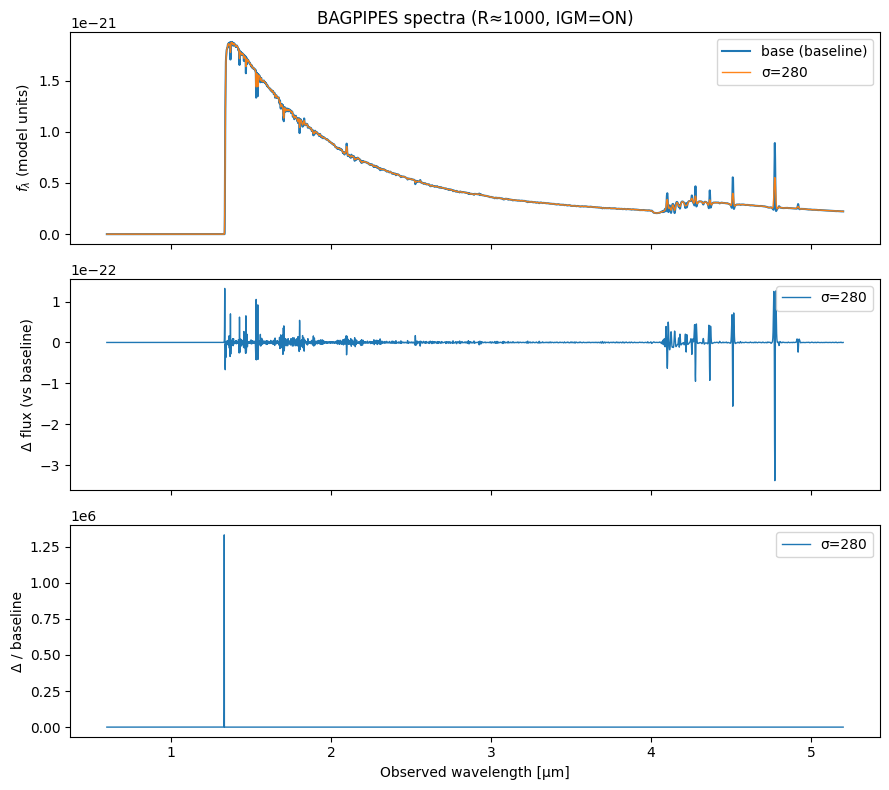

{'R': 1000,
 'igm': True,
 'lambda_A': array([ 6000.        ,  6002.00033337,  6004.00133363, ...,
        51974.82512971, 51992.15295923, 52009.48656566]),
 'spectra': {'base': array([4.45483496e-70, 4.34015016e-70, 4.18958519e-70, ...,
         2.22889790e-22, 2.22695314e-22, 2.22535648e-22]),
  'σ=280': array([4.46353222e-70, 4.35332874e-70, 4.20869956e-70, ...,
         2.22676879e-22, 2.22601170e-22, 2.22531026e-22])},
 'residuals': {'σ=280': array([ 8.69726800e-73,  1.31785739e-72,  1.91143692e-72, ...,
         -2.12910960e-25, -9.41448064e-26, -4.62223046e-27])},
 'norm_residuals': {'σ=280': array([ 8.69726800e-43,  1.31785739e-42,  1.91143692e-42, ...,
         -9.55229751e-04, -4.22751625e-04, -2.07707416e-05])}}

In [ ]:
quick_compare([("base", {}), ("σ=280", {"veldisp": 280})], R=1000, igm=True)


/tmp/ipython-input-2046090748.py:126: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend(loc="best"); axes[2].legend(loc="best")


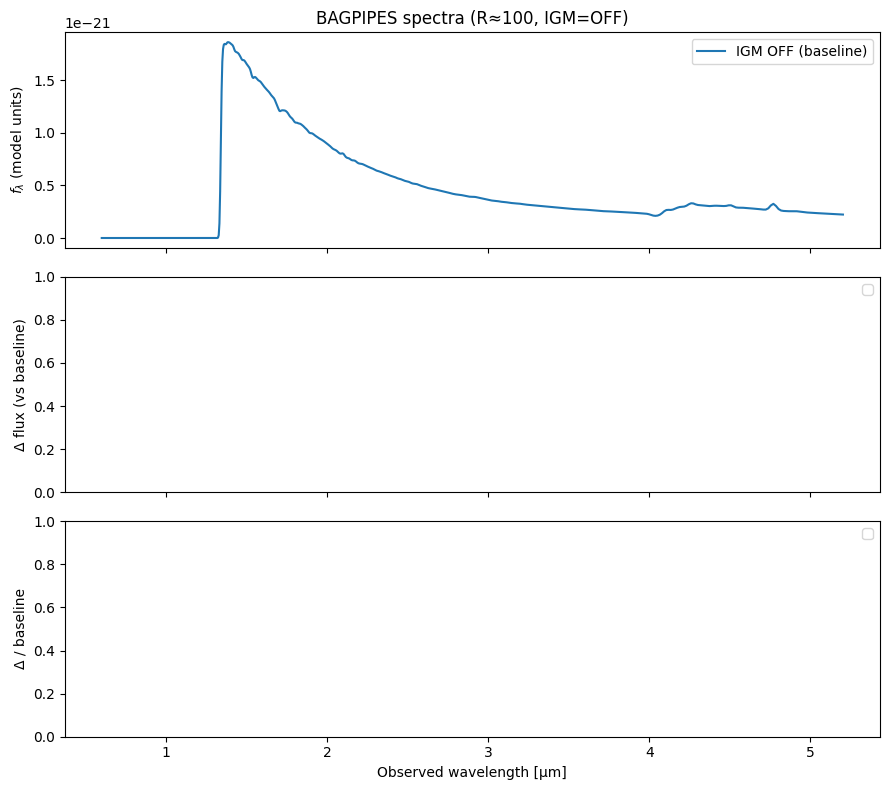

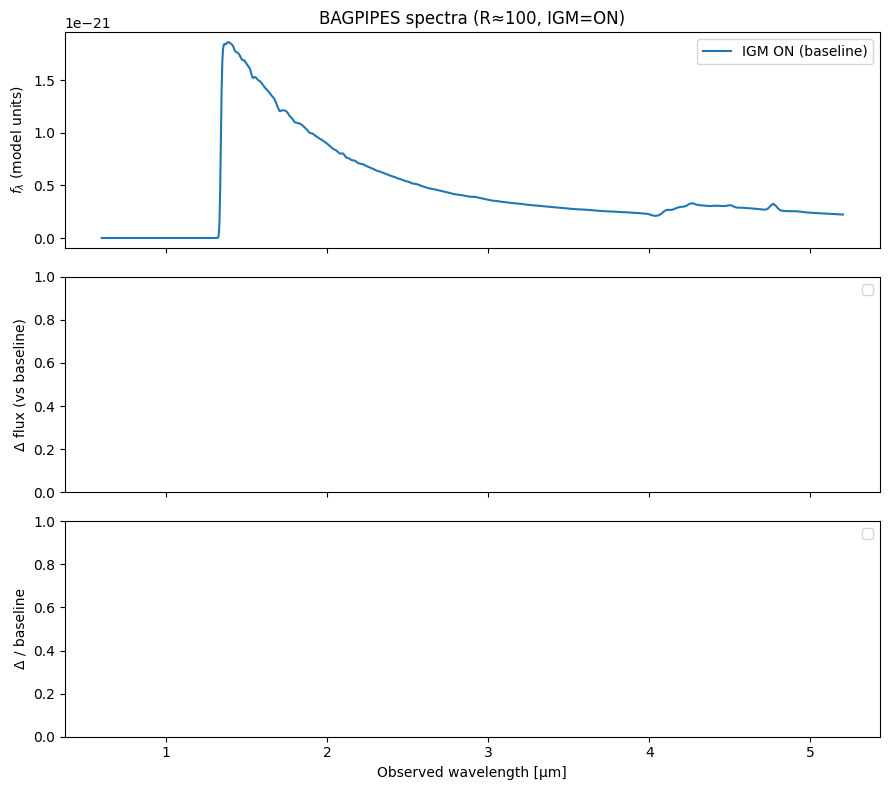

{'R': 100,
 'igm': True,
 'lambda_A': array([ 6000.        ,  6020.0333704 ,  6040.13363012,  6060.30100251,
         6080.53571163,  6100.83798232,  6121.20804016,  6141.64611149,
         6162.15242339,  6182.72720372,  6203.37068108,  6224.08308485,
         6244.86464515,  6265.71559291,  6286.6361598 ,  6307.62657826,
         6328.68708152,  6349.8179036 ,  6371.01927927,  6392.29144411,
         6413.63463448,  6435.04908753,  6456.53504118,  6478.09273418,
         6499.72240605,  6521.42429713,  6543.19864854,  6565.04570223,
         6586.96570094,  6608.95888822,  6631.02550845,  6653.16580681,
         6675.3800293 ,  6697.66842275,  6720.03123481,  6742.46871395,
         6764.98110948,  6787.56867153,  6810.23165108,  6832.97029995,
         6855.78487077,  6878.67561706,  6901.64279314,  6924.68665422,
         6947.80745633,  6971.00545637,  6994.2809121 ,  7017.63408213,
         7041.06522595,  7064.5746039 ,  7088.16247719,  7111.82910792,
         7135.57475905,  71

In [ ]:
# Flip the global igm flag in two calls:
quick_compare([("IGM OFF", {})], R=100, igm=False)
quick_compare([("IGM ON",  {})], R=100, igm=True)


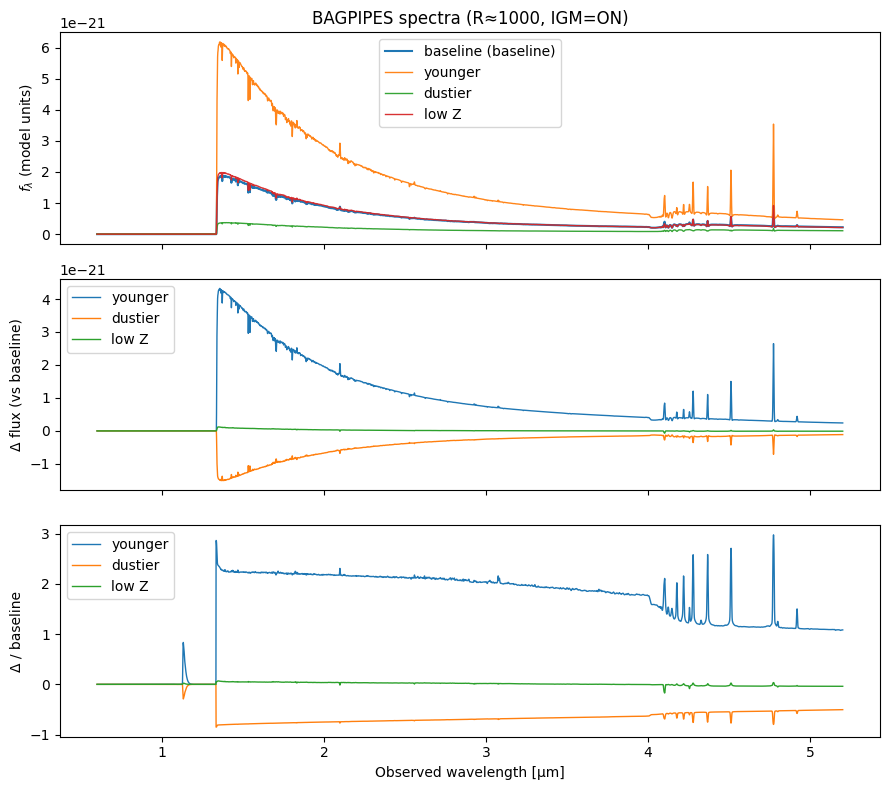

{'R': 1000,
 'igm': True,
 'lambda_A': array([ 6000.        ,  6002.00033337,  6004.00133363, ...,
        51974.82512971, 51992.15295923, 52009.48656566]),
 'spectra': {'baseline': array([4.45483496e-70, 4.34015016e-70, 4.18958519e-70, ...,
         2.22889790e-22, 2.22695314e-22, 2.22535648e-22]),
  'younger': array([1.86012657e-69, 1.81210360e-69, 1.74906141e-69, ...,
         4.64298710e-22, 4.63986514e-22, 4.63696703e-22]),
  'dustier': array([2.69122218e-71, 2.62313149e-71, 2.53369512e-71, ...,
         1.10519394e-22, 1.10445428e-22, 1.10384132e-22]),
  'low Z': array([5.26954216e-70, 5.13495311e-70, 4.95845299e-70, ...,
         2.14224573e-22, 2.14054804e-22, 2.13917823e-22])},
 'residuals': {'younger': array([1.41464308e-69, 1.37808859e-69, 1.33010289e-69, ...,
         2.41408919e-22, 2.41291200e-22, 2.41161055e-22]),
  'dustier': array([-4.18571274e-70, -4.07783702e-70, -3.93621568e-70, ...,
         -1.12370397e-22, -1.12249886e-22, -1.12151516e-22]),
  'low Z': array([ 8.

In [ ]:
quick_compare([
    ("baseline", {}),
    ("younger",  {"exponential": {"age": 0.1}}),
    ("dustier",  {"dust": {"Av": 0.8}}),
    ("low Z",    {"exponential": {"metallicity": 0.001}})
], R=1000, igm=True)


#FITTING GALAXY SPEC

In [ ]:
# ---- Galaxy spectrum with Lyα spike capping, using your redshift + DL setup ----

import numpy as np
from scipy.ndimage import gaussian_filter1d
import bagpipes as pipes
import bagpipes.config as cfg
from scipy.integrate import quad

# -----------------------------
# Globals / defaults (your values)
# -----------------------------
R_target  = 10000.0
lam_min_A = 0.60e4
lam_max_A = 5.20e4

# constant-R observed grid (uniform in ln λ, ~3 pix/FWHM)
dlnlam  = (1.0/R_target)/3.0
ln_grid = np.arange(np.log(lam_min_A), np.log(lam_max_A) + dlnlam, dlnlam)
lam_obs_grid = np.exp(ln_grid)  # Å

# bagpipes: avoid internal IGM
cfg.max_redshift = 30
for flag in ("apply_igm", "use_igm", "include_igm"):
    if hasattr(cfg, flag):
        setattr(cfg, flag, False)

# -----------------------------
# Cosmology (your function)
# -----------------------------
def luminosity_distance_cm(z, H0_kms_Mpc=70.0, Omega_m=0.3):
    c = 2.99792458e10  # cm/s
    H0 = H0_kms_Mpc * 1e5 / 3.085677581e24
    Om = Omega_m; Ol = 1.0 - Om
    Ez = lambda zp: np.sqrt(Om*(1.0+zp)**3 + Ol)
    chi = quad(lambda zp: 1.0/Ez(zp), 0.0, z, epsabs=0, epsrel=1e-6)[0]
    return (1.0+z) * (c/H0) * chi

# -----------------------------
# Core forward model
# -----------------------------
def galaxy_spectrum(
    z, logM, age, tau, Z, Av, logU, fesc,
    *,
    R=R_target,
    lam_min=lam_min_A, lam_max=lam_max_A,
    lya_cap_factor=3.0,      # cap Lyα peak to ≤ (factor × local continuum)
    lya_window_kms=600.0,    # half-width of the Lyα core to cap (in km/s)
    apply_igm=True,          # hard Lyα break (no flux blueward)
    veldisp_kms=80.0,        # intrinsic stellar velocity dispersion for BAGPIPES broadening (rest-frame)
    eta_birthcloud=3.0,      # extra dust for young stars
):
    """
    Returns (lam_obs, f_lambda_obs) on a constant-R grid. Units: f_lambda in BAGPIPES units / (4π D_L^2).
    The Lyα emission spike near 1215.67*(1+z) Å is "chopped" if it's too tall.
    """
    # --- Make rest-frame grid that comfortably covers obs/(1+z) ---
    pad = 1.05
    dln = (1.0 / R) / 3.0
    ln_grid_rest = np.arange(
        np.log((lam_min/(1.0+z))/pad),
        np.log((lam_max/(1.0+z))*pad) + dln,
        dln
    )
    lam_rest = np.exp(ln_grid_rest)

    # --- BAGPIPES components (no internal redshift or IGM) ---
    exp  = {"age": age, "tau": tau, "massformed": logM, "metallicity": Z}
    dust = {"type": "Calzetti", "Av": Av, "eta": eta_birthcloud}
    neb  = {"logU": logU, "f_esc": fesc}
    comp = {"redshift": 0.0, "t_bc": 0.01, "veldisp": veldisp_kms,
            "exponential": exp, "dust": dust, "nebular": neb}

    # --- Generate rest-frame luminosity spectrum L_lambda(λ_rest) ---
    m = pipes.model_galaxy(comp, spec_wavs=lam_rest)
    spec = np.asarray(m.spectrum)              # shape (N, 2) = [λ_rest, Lλ_rest]
    lam_rf, Llam_rf = spec[:, 0], spec[:, 1]

    # --- Shift to observed frame (your formulae) ---
    lam_of  = lam_rf * (1.0 + z)               # Å
    Llam_of = Llam_rf / (1.0 + z)              # L_lambda transforms with dλ
    # Interpolate onto our observed constant-R grid
    f_L_at_grid = np.interp(lam_obs_grid, lam_of, Llam_of, left=0.0, right=0.0)

    # --- Convert luminosity density to flux density using your D_L ---
    f_on = f_L_at_grid / (4.0 * np.pi * luminosity_distance_cm(z)**2)

    # --- Optional: apply a hard IGM Lyα break (no flux blueward of Lyα) ---
    lya_obs = 1215.67 * (1.0 + z)              # Å
    if apply_igm:
        f_on = np.where(lam_obs_grid >= lya_obs, f_on, 0.0)

    # --- Cap (chop) an overly tall Lyα emission spike BEFORE LSF smoothing ---
    # Define a small ±Δλ window in velocity space around Lyα
    c_kms = 2.99792458e5
    dln_win = lya_window_kms / c_kms           # since Δlnλ ≈ v/c for small v
    # indices within |Δlnλ| ≤ dln_win
    ln_lam = np.log(lam_obs_grid)
    mask_core = np.abs(ln_lam - np.log(lya_obs)) <= dln_win

    if np.any(mask_core):
        # Estimate a local continuum just redward of the line core (avoid the core itself).
        # Take a broader shoulder region: +1000→+5000 km/s to stay away from the core.
        dln_lo, dln_hi = 1000.0/c_kms, 5000.0/c_kms
        cont_mask = (ln_lam >= np.log(lya_obs) + dln_lo) & (ln_lam <= np.log(lya_obs) + dln_hi)
        # Robust fallback if window is too narrow at spectrum edges:
        if not np.any(cont_mask):
            # use 1–3% in wavelength on the red side as a fallback
            cont_mask = (lam_obs_grid >= 1.01*lya_obs) & (lam_obs_grid <= 1.03*lya_obs)

        cont_level = np.median(f_on[cont_mask]) if np.any(cont_mask) else np.median(f_on)
        # Numerical guard in very faint continua
        cont_level = max(cont_level, 1e-40)

        cap_value = lya_cap_factor * cont_level
        # Cap the flux only inside the line core window
        f_on[mask_core] = np.minimum(f_on[mask_core], cap_value)

    # --- Convolve to target resolving power R (Gaussian in ln λ) ---
    sigma_ln  = (1.0 / R) / 2.355
    sigma_pix = sigma_ln / dln
    f_R = gaussian_filter1d(f_on, sigma_pix, mode="nearest")

    return lam_obs_grid, f_R


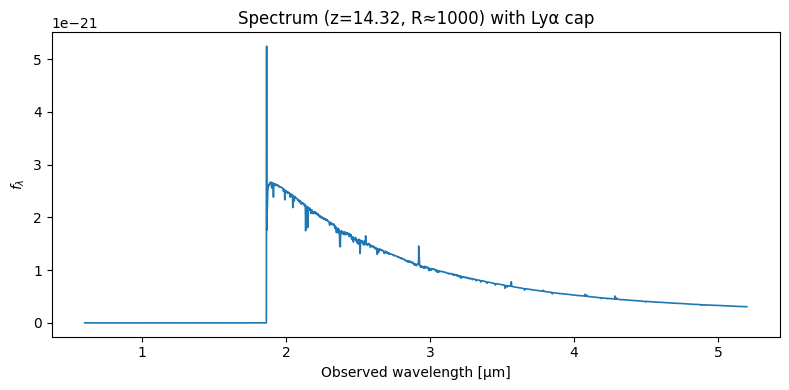

In [ ]:
base = {"z": 14.32, "logM": 8.8, "age": 0.03, "tau": 0.03,
        "Z": 0.01, "Av": 0.25, "logU": -2.5, "fesc": 0.7}

lam, flux = galaxy_spectrum(**base,
                            R=1000,           # your grid/LSF
                            lya_cap_factor=2,  # cap Lyα to 3× local continuum
                            lya_window_kms=600,
                            apply_igm=True,
                            veldisp_kms=80)

plt.figure(figsize=(8,4))
plt.plot(lam/1e4, flux, lw=1.2)
plt.xlabel("Observed wavelength [μm]")
plt.ylabel(r"$f_\lambda$")
plt.title(f"Spectrum (z={base['z']:.2f}, R≈{1000}) with Lyα cap")
plt.tight_layout(); plt.show()


In [ ]:
from scipy.interpolate import interp1d
import numpy as np

def make_model_interpolator(params, *, R=1000, lya_cap_factor=3.0, lya_window_kms=600.0,
                            apply_igm=True, veldisp_kms=80.0, kind="linear",
                            fill_value=0.0):
    """
    Build a model spectrum with galaxy_spectrum(**params) and return an interpolator
    f(lam_um) -> flux at that wavelength (microns). Outside the model range returns fill_value.

    params should be a dict with keys: z, logM, age, tau, Z, Av, logU, fesc
    """
    lam_A, flux = galaxy_spectrum(**params,
                                  R=R,
                                  lya_cap_factor=lya_cap_factor,
                                  lya_window_kms=lya_window_kms,
                                  apply_igm=apply_igm,
                                  veldisp_kms=veldisp_kms)
    lam_um = lam_A / 1e4  # Å -> µm
    # Ensure strictly increasing for interp1d (galaxy_spectrum already is, but just in case)
    order = np.argsort(lam_um)
    lam_um = lam_um[order]
    flux = flux[order]
    return interp1d(lam_um, flux, kind=kind, bounds_error=False, fill_value=fill_value)

def model_flux_at_obs_lambda(obs_lambda_um, params, **kwargs):
    """
    Convenience wrapper: returns model flux evaluated at the provided obs_lambda (µm).
    kwargs are passed through to make_model_interpolator (e.g., R, apply_igm, etc.).
    """
    f = make_model_interpolator(params, **kwargs)
    return f(np.asarray(obs_lambda_um))


In [ ]:
from scipy.optimize import minimize
import numpy as np

# --- sensible soft bounds for each parameter (used only for a penalty) ---
_DEFAULT_BOUNDS = {
    "z":     (5.0, 16.0),
    "logM":  (7.0, 10),
    "age":   (1e-3, 1.0),    # Gyr
    "tau":   (1e-3, 2.0),    # Gyr
    "Z":     (1e-4, 0.05),    # Z/Zsun
    "Av":    (0.0, 3.0),     # mag
    "logU":  (-4.5, -0.5),
    "fesc":  (0.0, 1.0),
}



from scipy.optimize import minimize
import numpy as np

def _params_to_vector(params, fit_keys, log_keys=()):
    """Build optimizer vector from params; take log10 for keys in log_keys."""
    x = []
    for k in fit_keys:
        v = float(params[k])
        x.append(np.log10(v) if (k in log_keys) else v)
    return np.array(x, dtype=float)

def _vector_to_params(x, base_params, fit_keys, log_keys=()):
    """Map optimizer vector back to physical params; 10** for keys in log_keys."""
    p = dict(base_params)
    for k, v in zip(fit_keys, x):
        p[k] = float(10.0**v) if (k in log_keys) else float(v)
    return p

def _mse_on_subset(lam_um_subset, flux_subset, model_params, **interp_kwargs):
    mflux = model_flux_at_obs_lambda(lam_um_subset, model_params, **interp_kwargs) * 1e21
    r = flux_subset - mflux
    return float(np.mean(r*r))

def fit_spectrum_nelder_mead_mse(
    obs_lambda_um,
    obs_flux,
    start_params,
    fit_keys=("z","logM","Av","age","Z"),
    log_keys=(),                   # NEW: keys to optimize in log10 space
    nm_options=None,
    fit_mask=None,
    R=10000,
    apply_igm=True,
    lya_cap_factor=3.0,
    lya_window_kms=600.0,
    veldisp_kms=80.0,
    kind="linear",
    fill_value=0.0,
):
    """
    Nelder–Mead fit minimizing MSE on an optional wavelength subset.
    'log_keys' tells the optimizer to search in log10 for those parameters
    (useful for strictly-positive params like age, tau, Z).
    """
    if isinstance(fit_keys, str):
        fit_keys = (fit_keys,)
    else:
        fit_keys = tuple(fit_keys)
    log_keys = set(log_keys)

    if fit_mask is None:
        lam_fit = obs_lambda_um
        flux_fit = obs_flux
    else:
        mask = np.asarray(fit_mask, dtype=bool)
        lam_fit = obs_lambda_um[mask]
        flux_fit = obs_flux[mask]

    # Initial vector (log-transform where requested)
    x0 = _params_to_vector(start_params, fit_keys, log_keys=log_keys)

    def objective(x):
        p = _vector_to_params(x, start_params, fit_keys, log_keys=log_keys)
        return _mse_on_subset(
            lam_fit, flux_fit, p,
            R=R, apply_igm=apply_igm,
            lya_cap_factor=lya_cap_factor, lya_window_kms=lya_window_kms,
            veldisp_kms=veldisp_kms, kind=kind, fill_value=fill_value
        )

    res = minimize(
        objective, x0, method="Nelder-Mead",
        options={"maxiter": 100, "xatol": 1e-4, "fatol": 1e-6, **(nm_options or {})}
    )

    best = _vector_to_params(res.x, start_params, fit_keys, log_keys=log_keys)
    best_flux_full = model_flux_at_obs_lambda(
        obs_lambda_um, best,
        R=R, apply_igm=apply_igm,
        lya_cap_factor=lya_cap_factor, lya_window_kms=lya_window_kms,
        veldisp_kms=veldisp_kms, kind=kind, fill_value=fill_value
    )

    return {"result": res, "best_params": best, "best_model_flux": best_flux_full, "fit_mask": fit_mask}


'''
def _params_to_vector(params, fit_keys):
    return np.array([params[k] for k in fit_keys], dtype=float)

def _vector_to_params(x, base_params, fit_keys):
    p = dict(base_params)
    for k, v in zip(fit_keys, x):
        p[k] = float(v)
    return p

def _mse(obs_lambda_um, obs_flux, model_params, **interp_kwargs):
    mflux = model_flux_at_obs_lambda(obs_lambda_um, model_params, **interp_kwargs)*1e21
    r = obs_flux - mflux
    return float(np.mean(r*r))

def fit_spectrum_nelder_mead_mse(
    obs_lambda_um,
    obs_flux,
    start_params,
    fit_keys=("z","logM","Av","age","Z"),
    nm_options=None,
    # kwargs forwarded to make_model_interpolator / galaxy_spectrum
    R=10000,
    apply_igm=True,
    lya_cap_factor=3.0,
    lya_window_kms=600.0,
    veldisp_kms=80.0,
    kind="linear",
    fill_value=0.0,
):
    """
    Nelder–Mead fit minimizing plain MSE between observed flux and model.
    - obs_lambda_um, obs_flux: arrays; wavelength in microns, flux in your units
    - start_params: dict with all physical params {z, logM, age, tau, Z, Av, logU, fesc}
    - fit_keys: iterable of parameter names to optimize
    Returns: dict(result=OptimizeResult, best_params=dict, best_model_flux=array)
    """
    fit_keys = tuple(fit_keys)
    x0 = _params_to_vector(start_params, fit_keys)

    def objective(x):
        p = _vector_to_params(x, start_params, fit_keys)
        return _mse(
            obs_lambda_um, obs_flux, p,
            R=R, apply_igm=apply_igm,
            lya_cap_factor=lya_cap_factor, lya_window_kms=lya_window_kms,
            veldisp_kms=veldisp_kms, kind=kind, fill_value=fill_value
        )

    res = minimize(
        objective, x0, method="Nelder-Mead",
        options={"maxiter": 20, "xatol": 1e-4, "fatol": 1e-6, **(nm_options or {})}
    )

    best = _vector_to_params(res.x, start_params, fit_keys)
    best_flux = model_flux_at_obs_lambda(
        obs_lambda_um, best,
        R=R, apply_igm=apply_igm,
        lya_cap_factor=lya_cap_factor, lya_window_kms=lya_window_kms,
        veldisp_kms=veldisp_kms, kind=kind, fill_value=fill_value
    )
    return {"result": res, "best_params": best, "best_model_flux": best_flux}

def _params_to_vector(params, fit_keys):
    return np.array([params[k] for k in fit_keys], dtype=float)

def _vector_to_params(x, base_params, fit_keys):
    p = dict(base_params)
    for k, v in zip(fit_keys, x):
        p[k] = float(v)
    return p

def _penalty_out_of_bounds(pdict, bounds=_DEFAULT_BOUNDS, strength=1e6):
    """Quadratic penalty for stepping outside soft bounds."""
    pen = 0.0
    for k, (lo, hi) in bounds.items():
        if k not in pdict:
            continue
        v = pdict[k]
        if v < lo:
            d = (lo - v) / max(1e-12, hi - lo)
            pen += strength * d*d
        elif v > hi:
            d = (v - hi) / max(1e-12, hi - lo)
            pen += strength * d*d
    return pen

def _chi2(obs_lambda_um, obs_flux, model_params, obs_sigma=None, **interp_kwargs):
    mflux = model_flux_at_obs_lambda(obs_lambda_um, model_params, **interp_kwargs)
    if obs_sigma is None:
        # fallback: 10% of |obs|, with a floor
        obs_sigma = np.maximum(0.1*np.maximum(1e-40, np.abs(obs_flux)), 1e-40)
    r = (obs_flux - mflux) / obs_sigma
    return float(np.sum(r*r))

def fit_spectrum_nelder_mead(
    obs_lambda_um,
    obs_flux,
    start_params,
    fit_keys=("z","logM","Av","age","Z"),
    obs_sigma=None,
    bounds=_DEFAULT_BOUNDS,
    nm_options=None,
    # kwargs forwarded to make_model_interpolator / galaxy_spectrum
    R=10000,
    apply_igm=True,
    lya_cap_factor=3.0,
    lya_window_kms=600.0,
    veldisp_kms=80.0,
    kind="linear",
    fill_value=0.0,
):
    """
    Nelder–Mead fit to match your observed spectrum.
    - obs_lambda_um, obs_flux: arrays, wavelength in microns, flux in your units
    - start_params: dict with keys of all physical params {z, logM, age, tau, Z, Av, logU, fesc}
    - fit_keys: iterable of parameter names to optimize
    - obs_sigma: optional per-pixel uncertainties (same units as obs_flux)
    Returns: dict(result=OptimizeResult, best_params=dict, best_model_flux=array)
    """
    fit_keys = tuple(fit_keys)
    x0 = _params_to_vector(start_params, fit_keys)

    def objective(x):
        p = _vector_to_params(x, start_params, fit_keys)
        chi2 = _chi2(
            obs_lambda_um, obs_flux, p, obs_sigma,
            R=R, apply_igm=apply_igm, lya_cap_factor=lya_cap_factor,
            lya_window_kms=lya_window_kms, veldisp_kms=veldisp_kms,
            kind=kind, fill_value=fill_value
        )
        pen = _penalty_out_of_bounds(p, bounds=bounds, strength=1e6)
        return chi2 + pen

    res = minimize(
        objective, x0, method="Nelder-Mead",
        options={"maxiter": 10, "xatol": 1e-4, "fatol": 1e-4, **(nm_options or {})}
    )

    best = _vector_to_params(res.x, start_params, fit_keys)
    best_flux = model_flux_at_obs_lambda(
        obs_lambda_um, best,
        R=R, apply_igm=apply_igm, lya_cap_factor=lya_cap_factor,
        lya_window_kms=lya_window_kms, veldisp_kms=veldisp_kms,
        kind=kind, fill_value=fill_value
    )
    return {"result": res, "best_params": best, "best_model_flux": best_flux}
'''

'\ndef _params_to_vector(params, fit_keys):\n    return np.array([params[k] for k in fit_keys], dtype=float)\n\ndef _vector_to_params(x, base_params, fit_keys):\n    p = dict(base_params)\n    for k, v in zip(fit_keys, x):\n        p[k] = float(v)\n    return p\n\ndef _mse(obs_lambda_um, obs_flux, model_params, **interp_kwargs):\n    mflux = model_flux_at_obs_lambda(obs_lambda_um, model_params, **interp_kwargs)*1e21\n    r = obs_flux - mflux\n    return float(np.mean(r*r))\n\ndef fit_spectrum_nelder_mead_mse(\n    obs_lambda_um,\n    obs_flux,\n    start_params,\n    fit_keys=("z","logM","Av","age","Z"),\n    nm_options=None,\n    # kwargs forwarded to make_model_interpolator / galaxy_spectrum\n    R=10000,\n    apply_igm=True,\n    lya_cap_factor=3.0,\n    lya_window_kms=600.0,\n    veldisp_kms=80.0,\n    kind="linear",\n    fill_value=0.0,\n):\n    """\n    Nelder–Mead fit minimizing plain MSE between observed flux and model.\n    - obs_lambda_um, obs_flux: arrays; wavelength in micr

In [ ]:
# Observed
import pandas as pd
import numpy as np

df = pd.read_csv("JZ14_spec.csv")
obs_lambda = np.array(df["Wavelength"])      # µm
obs_flux   = np.array(df[" Flux"])         # keep as-is (model *1e21 inside _mse)

# Base & which params to fit (z fixed)
base = {"z": 14.18, "logM": 8.4, "age": 0.03, "tau": 0.03,
        "Z": 0.01, "Av": 0.15, "logU": -2.5, "fesc": 0.7}
fit_keys = ("logM", "age", "tau", "Z", "Av", "logU", "fesc")
log_keys = ("age", "tau", "Z")   # <- optimize these in log10 space

# ---- build red-side-only mask (≥ 1.03 × Lyα) ----
lya_um = 1215.67 * (1.0 + base["z"]) / 1e4
lam_min_fit = 1.1 * lya_um
fit_mask = (obs_lambda >= lam_min_fit)
'''
# ---- MSE-based Nelder–Mead (no penalties), fitting only masked region ----
out = fit_spectrum_nelder_mead_mse(
    obs_lambda, obs_flux, start_params=base,
    fit_keys=fit_keys, log_keys=log_keys,   # <-- added log_keys
    fit_mask=fit_mask,
    R=1000, apply_igm=True, lya_cap_factor=1.0,
    lya_window_kms=600.0, veldisp_kms=80.0
)

print("Converged:", out["result"].success, out["result"].message)
print("Best params:", out["best_params"])
print("Best MSE:", out["result"].fun)

# Inspect fit (full spectrum shown; optimization used only red side)
plt.figure(figsize=(9,4))
plt.plot(obs_lambda, obs_flux, lw=1, label="Observed")
plt.plot(obs_lambda, out["best_model_flux"]*1e21, lw=1.4, label="Best-fit model (MSE)")
plt.axvline(lam_min_fit, ls="--", alpha=0.7, label="fit ≥ 1.03×Lyα")
plt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\lambda$")
plt.legend(); plt.tight_layout(); plt.show()
'''

<>:38: SyntaxWarning: invalid escape sequence '\l'
<>:38: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipython-input-2682717981.py:38: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\lambda$")


'\n# ---- MSE-based Nelder–Mead (no penalties), fitting only masked region ----\nout = fit_spectrum_nelder_mead_mse(\n    obs_lambda, obs_flux, start_params=base,\n    fit_keys=fit_keys, log_keys=log_keys,   # <-- added log_keys\n    fit_mask=fit_mask,\n    R=1000, apply_igm=True, lya_cap_factor=1.0,\n    lya_window_kms=600.0, veldisp_kms=80.0\n)\n\nprint("Converged:", out["result"].success, out["result"].message)\nprint("Best params:", out["best_params"])\nprint("Best MSE:", out["result"].fun)\n\n# Inspect fit (full spectrum shown; optimization used only red side)\nplt.figure(figsize=(9,4))\nplt.plot(obs_lambda, obs_flux, lw=1, label="Observed")\nplt.plot(obs_lambda, out["best_model_flux"]*1e21, lw=1.4, label="Best-fit model (MSE)")\nplt.axvline(lam_min_fit, ls="--", alpha=0.7, label="fit ≥ 1.03×Lyα")\nplt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\\lambda$")\nplt.legend(); plt.tight_layout(); plt.show()\n'

In [ ]:
import numpy as np
import pandas as pd
from copy import deepcopy

# ---------- Monte-Carlo settings ----------
N_SAMPLES = 30
REL_SIGMA = 0.20          # 20% flux uncertainty
SEED = 42                 # for reproducibility

rng = np.random.default_rng(SEED)

# Per-point Gaussian sigma as 20% of |flux|
flux_sigma = REL_SIGMA * np.abs(obs_flux)

# Draw (N_SAMPLES × N_points) noisy flux realizations
# Each row is one "experiment"
flux_samples = rng.normal(loc=obs_flux, scale=flux_sigma, size=(N_SAMPLES, obs_flux.size))

# (Optional) If your fitter expects strictly positive f_lambda, clip small/negatives:
# flux_samples = np.clip(flux_samples, a_min=np.finfo(float).tiny, a_max=None)

records = []
for i in range(N_SAMPLES):
    flux_i = flux_samples[i]

    # Run the exact same fit as your baseline, but with the noisy flux
    out_i = fit_spectrum_nelder_mead_mse(
        obs_lambda, flux_i,
        start_params=deepcopy(base),       # keep the same starting point; deepcopy for safety
        fit_keys=fit_keys,
        log_keys=log_keys,
        fit_mask=fit_mask,
        R=1000, apply_igm=True,
        lya_cap_factor=1.0,
        lya_window_kms=600.0,
        veldisp_kms=80.0
    )

    res = out_i["result"]
    bp  = out_i["best_params"]

    # Pull just the parameters you’re actually fitting (plus anything else you want to track)
    row = {
        "sample_id": i,
        "converged": bool(res.success),
        "message":   str(res.message),
        "best_mse":  float(res.fun),
        # fitted keys
        "logM": float(bp.get("logM", np.nan)),
        "age":  float(bp.get("age",  np.nan)),
        "tau":  float(bp.get("tau",  np.nan)),
        # fixed keys you might want for context
        "z":    float(bp.get("z", base["z"])),
        "Z":    float(bp.get("Z", base["Z"])),
        "Av":   float(bp.get("Av", base["Av"])),
        "logU": float(bp.get("logU", base["logU"])),
        "fesc": float(bp.get("fesc", base["fesc"])),
    }
    records.append(row)

# Save results
df_mc = pd.DataFrame.from_records(records)

# (Optional) ensure MSE is the last column for quick inspection
cols_order = [c for c in df_mc.columns if c not in ("best_mse",)]
cols_order += ["best_mse"]
df_mc = df_mc[cols_order]

csv_path = "flux20pct_mc30_bestfits.csv"
df_mc.to_csv(csv_path, index=False)
print(f"Saved {len(df_mc)} rows to {csv_path}")

# (Optional) quick summary
print(df_mc[["converged"]].value_counts())
print(df_mc.describe())


Saved 30 rows to flux20pct_mc30_bestfits.csv
converged
False        30
Name: count, dtype: int64
            logM        age        tau   best_mse
count  30.000000  30.000000  30.000000  30.000000
mean    8.663997   0.033321   0.030307   0.095439
std     0.087072   0.005745   0.003142   0.006756
min     8.537565   0.025134   0.023580   0.077814
25%     8.602622   0.029496   0.028307   0.092246
50%     8.658873   0.032702   0.029933   0.094917
75%     8.721822   0.037378   0.032179   0.099604
max     8.848949   0.045695   0.036157   0.106792


#####COLAB PARALEL PROCESS

In [ ]:
# --- Option B: joblib (process-based) parallel MC fits ---

!pip -q install joblib

import os, numpy as np, pandas as pd
from copy import deepcopy
from joblib import Parallel, delayed

# Limit BLAS threads *before* creating the pool (prevents oversubscription)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# ---------- Monte-Carlo settings ----------
N_SAMPLES = 30
REL_SIGMA = 0.20          # 20% flux uncertainty
BASE_SEED = 42            # base seed for reproducibility across runs
N_JOBS = -1               # -1 = use all available CPUs; or set to an int
BATCH_SIZE = 1            # keep 1 for long-running tasks (reduces latency/overhead)

# Per-point Gaussian sigma as 20% of |flux|
flux_sigma = REL_SIGMA * np.abs(obs_flux)

def run_one(i, base_seed=BASE_SEED):
    """
    One Monte-Carlo replicate:
    - draw a noisy flux realization
    - run the Nelder–Mead fit
    - return a compact dict with results
    """
    # Independent RNG per sample
    rng = np.random.default_rng((base_seed, i))
    flux_i = rng.normal(loc=obs_flux, scale=flux_sigma, size=obs_flux.size)

    # If fitter needs strictly positive fluxes, uncomment:
    # flux_i = np.clip(flux_i, a_min=np.finfo(float).tiny, a_max=None)

    out_i = fit_spectrum_nelder_mead_mse(
        obs_lambda, flux_i,
        start_params=deepcopy(base),   # deepcopy for safety; drop if your fitter never mutates
        fit_keys=fit_keys,
        log_keys=log_keys,
        fit_mask=fit_mask,
        R=1000, apply_igm=True,
        lya_cap_factor=1.0,
        lya_window_kms=600.0,
        veldisp_kms=80.0
    )

    res = out_i["result"]
    bp  = out_i["best_params"]

    return {
        "sample_id": i,
        "converged": bool(res.success),
        "message":   str(res.message),
        "best_mse":  float(res.fun),
        # fitted keys
        "logM": float(bp.get("logM", np.nan)),
        "age":  float(bp.get("age",  np.nan)),
        "tau":  float(bp.get("tau",  np.nan)),
        # fixed/context keys
        "z":    float(bp.get("z", base["z"])),
        "Z":    float(bp.get("Z", base["Z"])),
        "Av":   float(bp.get("Av", base["Av"])),
        "logU": float(bp.get("logU", base["logU"])),
        "fesc": float(bp.get("fesc", base["fesc"])),
    }

# ---- Run parallel (or set N_JOBS=1 for serial) ----
records = Parallel(n_jobs=N_JOBS, prefer="processes", batch_size=BATCH_SIZE)(
    delayed(run_one)(i) for i in range(N_SAMPLES)
)

# ---- Assemble and save results (identical to your original) ----
df_mc = pd.DataFrame.from_records(records)

# Ensure MSE is last for quick inspection
cols_order = [c for c in df_mc.columns if c != "best_mse"] + ["best_mse"]
df_mc = df_mc[cols_order]

csv_path = "flux20pct_mc30_bestfits.csv"
df_mc.to_csv(csv_path, index=False)
print(f"Saved {len(df_mc)} rows to {csv_path}")

# Quick summary
print(df_mc[["converged"]].value_counts())
print(df_mc.describe())


Saved 30 rows to flux20pct_mc30_bestfits.csv
converged
False        30
Name: count, dtype: int64
       sample_id       logM        age        tau             z          Z  \
count  30.000000  30.000000  30.000000  30.000000  3.000000e+01  30.000000   
mean   14.500000   8.745695   0.037787   0.025799  1.418000e+01   0.009779   
std     8.803408   0.086772   0.007145   0.003961  5.420172e-15   0.003692   
min     0.000000   8.601560   0.028918   0.014362  1.418000e+01   0.001467   
25%     7.250000   8.697535   0.033778   0.023915  1.418000e+01   0.008654   
50%    14.500000   8.724377   0.035692   0.025961  1.418000e+01   0.010123   
75%    21.750000   8.798292   0.040513   0.028650  1.418000e+01   0.012167   
max    29.000000   8.998464   0.064935   0.031178  1.418000e+01   0.016247   

              Av       logU       fesc   best_mse  
count  30.000000  30.000000  30.000000  30.000000  
mean    0.149592  -2.567521   0.678443   0.096303  
std     0.006045   0.160615   0.112364   0.0

In [ ]:
# --- Option B: joblib (process-based) parallel MC fits + timing benchmark ---

!pip -q install joblib

import os, time, numpy as np, pandas as pd
from copy import deepcopy
from joblib import Parallel, delayed

# 1) Prevent BLAS oversubscription (set BEFORE creating any pools)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# 2) ---- Settings ----
N_SAMPLES   = 30          # main MC run size
REL_SIGMA   = 0.20        # 20% flux uncertainty
BASE_SEED   = 42          # reproducible draws
N_JOBS      = -1          # -1 = all CPUs
BATCH_SIZE  = 1           # good for long-running fits
RUN_BENCH   = True        # set False to skip timing
BENCH_SAMPLES = min(10, N_SAMPLES)  # use a small subset for quick timing

# 3) Precompute per-point sigma
flux_sigma = REL_SIGMA * np.abs(obs_flux)

# 4) Core worker (one Monte-Carlo replicate)
def run_one(i, base_seed=BASE_SEED):
    rng = np.random.default_rng((base_seed, i))
    flux_i = rng.normal(loc=obs_flux, scale=flux_sigma, size=obs_flux.size)
    # If needed:
    # flux_i = np.clip(flux_i, a_min=np.finfo(float).tiny, a_max=None)

    out_i = fit_spectrum_nelder_mead_mse(
        obs_lambda, flux_i,
        start_params=deepcopy(base),   # drop deepcopy if fitter never mutates
        fit_keys=fit_keys, log_keys=log_keys, fit_mask=fit_mask,
        R=1000, apply_igm=True,
        lya_cap_factor=1.0, lya_window_kms=600.0, veldisp_kms=80.0
    )
    res = out_i["result"]; bp = out_i["best_params"]

    return {
        "sample_id": i,
        "converged": bool(res.success),
        "message":   str(res.message),
        "best_mse":  float(res.fun),
        "logM": float(bp.get("logM", np.nan)),
        "age":  float(bp.get("age",  np.nan)),
        "tau":  float(bp.get("tau",  np.nan)),
        "z":    float(bp.get("z", base["z"])),
        "Z":    float(bp.get("Z", base["Z"])),
        "Av":   float(bp.get("Av", base["Av"])),
        "logU": float(bp.get("logU", base["logU"])),
        "fesc": float(bp.get("fesc", base["fesc"])),
    }

# 5) (Optional) Timing benchmark (uses disjoint indices so it doesn't affect main run)
def time_serial(n, offset=10_000):
    t0 = time.perf_counter()
    recs = [run_one(offset + i) for i in range(n)]
    t1 = time.perf_counter()
    return t1 - t0, recs

def time_parallel(n, n_jobs=N_JOBS, batch_size=BATCH_SIZE, offset=10_000):
    t0 = time.perf_counter()
    recs = Parallel(n_jobs=n_jobs, prefer="processes", batch_size=batch_size)(
        delayed(run_one)(offset + i) for i in range(n)
    )
    t1 = time.perf_counter()
    return t1 - t0, recs

print("vCPUs detected:", os.cpu_count())

if RUN_BENCH and BENCH_SAMPLES > 0:
    # quick warm-up to avoid first-call overhead in benchmark
    _ = run_one(999999)

    t_ser, _ = time_serial(BENCH_SAMPLES)
    t_par, _ = time_parallel(BENCH_SAMPLES)

    speedup    = t_ser / t_par
    efficiency = speedup / (os.cpu_count() or 1)

    print(f"\n[Benchmark on {BENCH_SAMPLES} fits]")
    print(f"Serial:   {t_ser:.2f} s  (~{t_ser/BENCH_SAMPLES:.3f} s/fit)")
    print(f"Parallel: {t_par:.2f} s  (~{t_par/BENCH_SAMPLES:.3f} s/fit)")
    print(f"Speedup:  {speedup:.2f}×   |   Parallel efficiency: {100*efficiency:.1f}%")

# 6) Main parallel Monte-Carlo run (indices 0..N_SAMPLES-1)
records = Parallel(n_jobs=N_JOBS, prefer="processes", batch_size=BATCH_SIZE)(
    delayed(run_one)(i) for i in range(N_SAMPLES)
)

# 7) Assemble, save, summarize (same as your original)
df_mc = pd.DataFrame.from_records(records)
cols_order = [c for c in df_mc.columns if c != "best_mse"] + ["best_mse"]
df_mc = df_mc[cols_order]

csv_path = "flux20pct_mc30_bestfits.csv"
df_mc.to_csv(csv_path, index=False)
print(f"\nSaved {len(df_mc)} rows to {csv_path}")
print(df_mc[["converged"]].value_counts())
print(df_mc.describe())


vCPUs detected: 2


KeyboardInterrupt: 

####DARK STAR

In [ ]:
# Import relevant packages.

import matplotlib.pyplot as plt
import numpy as np
import math
import scipy.integrate as integrate
import scipy.special as special
from scipy.interpolate import interp1d
import matplotlib.ticker
from scipy.integrate import quad
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from matplotlib.ticker import FormatStrFormatter
import pandas as pd
from array import *
matplotlib.rcParams.update(matplotlib.rcParamsDefault)
matplotlib.rcParams['mathtext.fontset'] = 'stix'
#matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['axes.grid'] = False
matplotlib.rcParams['image.origin'] = 'lower'
import matplotlib.pyplot as plt


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize


#define parameters/ constants in cgs units
c=3.0*1e10 #speed of light
H_0=7.2*1e6 #hubble's constant
h=6.63*1e-27 #Planck's constant
k_b=1.38*1e-16 #Boltzmann's constant
Omega_M=0.27 #matter density fraction
Omega_Alpha=0.73 #Dark energy density fraction
D_H=c/H_0*3.086*1e24 #hubble distance


# Functions used to redshift SEDs

# convert individual string in the format of 'x.xxxD+xx' to decimal number
def strtonum(strD):
    dot=1  #position of dot
    digit=99999 #position of D
    Num=0.0 #converted number
    sign=0 #position of the sign
    for i in range(len(strD)):
        if strD[i]=='+':
            sign=1;
        if strD[i]=='-':
            sign=-1
        if i==0:
            Num+=int(float(strD[i]))
        if strD[i]=='D' or strD[i]=='E':
            digit=i
        if sign==0:
            if i>dot and i<digit:
                Num+=int(strD[i])*10**(-(i-1))
        elif i>digit+1 and sign==1:
                Num*=10**(int(strD[i])*10**(len(strD)-i-1))
        elif i>digit+1 and sign==-1:
                Num*=10**(-int(strD[i])*10**(len(strD)-i-1))
    return Num

# convert to an array
def convertdata(data):
    array=[]
    for i in range(len(data)):
        array.insert(i,strtonum(data[i]))
    return array

#convert freq at emission to observed lambda(in microns) since we want to plot flux vs.wavelength
def freqtolam(data,z):
    freq=convertdata(data[0:,0])
    Lambda_obs=[]
    for i in range(len(freq)):
        if c/freq[i]*(1+z)*1e4<=10:
            Lambda_obs.insert(i,c/freq[i]*(1+z)*1e4)
    return Lambda_obs

# Redshift the SED, flux is in units of nJy
def shftspecTLU(data,z,R):
    freq=convertdata(data[0:,0]) #import the converted data
    flux=convertdata(data[0:,1])
    #eddfactor=data[0:,2]
    if z!=0:
        I = integrate.quad(lambda x: D_H*1/math.sqrt(Omega_M*(1+x)**3+Omega_Alpha), 0, z)
        DC_z=I[0]-I[1]
        DL_z=(1+z)*DC_z
        fluxobs=[]
        for i in range(len(freqtolam(data,z))):
            fluxobs.insert(i,4*np.pi*flux[i]*(1+z)*R**2/DL_z**2*1e32)
            #follow eq8 of: https://academic.oup.com/mnras/article/422/3/2164/1043351, if source z>0
        #flux=list(map(lambda x: ,Lambda))
    else:
        fluxobs=[]
        for i in range(len(freqtolam(data,z))):
            fluxobs.insert(i,4*np.pi*flux[i]*1e32)
    return fluxobs


def nanojansky_to_ergs_per_cm2_per_A(njy, wavelength_micron):
    # Constants
    speed_of_light_cm_per_s = 29979245800  # Speed of light in cm/s

    # Convert nanoJansky to Jansky
    jy = njy * 1e-9  # 1 nanoJansky = 10^-9 Jansky

    # Convert Jansky to erg/s/cm²/Hz
    flux_density_hz = jy * 1e-23  # 1 Jansky = 10^-23 erg/s/cm²/Hz

    # Convert wavelength from Angstroms to centimeters
    wavelength_cm = wavelength_micron * 1e-4  # 1 Angstrom = 10^-8 cm

    # Convert erg/s/cm²/Hz to erg/s/cm²/Angstrom
    flux_density_angstrom = flux_density_hz * (speed_of_light_cm_per_s / (wavelength_cm**2))

    return flux_density_angstrom*10**-8*(10**21)

Masses = np.log10(np.array([10**5, 10**6, 10**7]))#in terms of 10^5
Radius = np.log10(np.array([5.83e+14, 9.12e+14, 1.45e+15]))
log_g = np.log10(10**np.array([1.591, 2.202, 2.8]))
temp = np.log10(np.array([14000, 19000, 27000]))
interpolation_mass_radii = interp1d(Masses, Radius, kind='linear', fill_value="extrapolate")
interpolation_mass_g = interp1d(Masses, log_g, kind='linear', fill_value="extrapolate")
interpolation_mass_temp = interp1d(Masses, temp, kind='linear', fill_value="extrapolate")




Mass_10_5 = np.array([1, 2, 3, 4, 5, 6, 7, 10, 20, 30, 40, 50, 60, 70, 90])
#Radius = np.array([5.83, 6.67, 7.22, 7.64, 7.98, 8.26, 8.51, 8.74, 8.94, 9.12])
data = np.array(['T3M1_0e5.13', 'T3M2_0e5.13', 'T3M3_0e5.13', 'T3M4_0e5.13', 'T3M5_0e5.13', 'T3M6_0e5.13', 'T3M7_0e5.13',   'T3M1_0e6.13', 'T3M2_0e6.13', 'T3M3_0e6.13', 'T3M4_0e6.13', 'T3M5_0e6.13', 'T3M6_0e6.13', 'T3M7_0e6.13',  'T3M9_0e6.13'])
print(data[13])


def interpolate_template_spec(data, mu, z, radius, min_wavelegnth, max_wavelength, obs_lambda):
    Spectrum_T3M6_31e5 = pd.read_csv(data
                                        ,header=None,sep='\s+')
    data_T3M6_31e5=Spectrum_T3M6_31e5.to_numpy()
    flux_8 = freqtolam(data_T3M6_31e5,z)
    spec_8 = shftspecTLU(data_T3M6_31e5, z, radius)
    flux_8 = np.array(flux_8)
    spec_8 = mu*np.array(spec_8)
    # Constants
    #print(flux_8)
    #print(spec_8)
    spec_now = np.zeros(len(flux_8))
    for i in range(len(flux_8)):
      spec_now[i] = nanojansky_to_ergs_per_cm2_per_A(spec_8[i], flux_8[i])
    indices = np.where((flux_8 >= min_wavelegnth) & (flux_8 <= max_wavelength))[0]

    # Step 2: Subset array1 using these indices
    subset_lambda = flux_8[indices]

    # Step 3: Use the same indices to subset array2
    subset_spec = spec_now[indices]
    lya_shift = 0.1216*(1+z)
    lam_cut = []
    flx_cut = []

    index = 0
    for i in subset_lambda:
        if i >lya_shift:
            lam_cut.append(i)
            flx_cut.append(1*subset_spec[index])
            index = index + 1
        else:
            lam_cut.append(i)
            flx_cut.append(0)

            index = index + 1
    lam_cut = np.array(lam_cut)
    flx_cut = np.array(flx_cut)

    interpolation_function = interp1d(lam_cut, flx_cut, kind='linear', bounds_error=False, fill_value='extrapolate')

    new_spec = interpolation_function(obs_lambda)

    #main_array = np.array([subset_lambda, subset_spec, new_spec])

    return new_spec

def spectrum_from_mass_z(mass_solar, z, obs_lambda,
                         min_wavelength=1.0, max_wavelength=5.28):
    """
    Parameters
    ----------
    mass_solar : float
        Input stellar mass in M_sun. e.g. 1.6e5 for 1.6×10^5 M_sun.
    z : float
        Redshift.
    obs_lambda : array-like
        Wavelength grid [micron] on which you want the spectrum returned.
    min_wavelength, max_wavelength : float
        Range [micron] to cut the template before interpolation to obs_lambda.

    Returns
    -------
    spec_on_grid : np.ndarray
        Spectrum on obs_lambda (same units as your interpolate_template_spec output).
    meta : dict
        Useful bookkeeping (which file was used, chosen grid mass, mu, etc.).
    """

    # 1) express input mass in "×10^5 M_sun" units to match your grid
    mass_10_5 = mass_solar / 1e5

    # 2) find nearest grid point in Mass_10_5 and corresponding file
    idx = int(np.argmin(np.abs(Mass_10_5 - mass_10_5)))
    chosen_grid_mass_10_5 = float(Mass_10_5[idx])   # e.g., 1, 2, ..., 90
    chosen_filename = str(data[idx])               # file name from your `data` array

    # 3) scale factor: mu = (input_mass / chosen_grid_mass)
    #    (per your request: e.g., 1.6/1 = 1.6 when using the 1×10^5 template)
    mu = mass_10_5 / chosen_grid_mass_10_5

    # 4) get a radius for the *actual* input mass (not the grid mass)
    #    your interpolation functions expect log10(M) with M in M_sun
    R_cm = 10.0 ** interpolation_mass_radii(np.log10(mass_solar))

    # 5) build spectrum on the requested wavelength grid
    spec_on_grid = interpolate_template_spec(
        chosen_filename, mu, z, R_cm,
        min_wavelength, max_wavelength,
        np.asarray(obs_lambda)
    )

    meta = {
        "input_mass_Msun": mass_solar,
        "input_mass_x1e5": mass_10_5,
        "chosen_grid_mass_x1e5": chosen_grid_mass_10_5,
        "mu": mu,
        "file": chosen_filename,
        "R_cm": R_cm,
        "z": z,
        "min_wavelength_micron": min_wavelength,
        "max_wavelength_micron": max_wavelength,
    }
    return np.asarray(spec_on_grid), meta


obs_lambda = np.linspace(1.0, 5.3, 4000)   # microns
spec, info = spectrum_from_mass_z(1.6e5, 11.0, obs_lambda)
print(info)
# spec matches obs_lambda one-to-one

plt.plot(obs_lambda, spec)
plt.show()

T3M7_0e6.13


<>:139: SyntaxWarning: invalid escape sequence '\s'
<>:139: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-3952124828.py:139: SyntaxWarning: invalid escape sequence '\s'
  ,header=None,sep='\s+')


FileNotFoundError: [Errno 2] No such file or directory: 'T3M2_0e5.13'

Optimization terminated successfully.
         Current function value: 0.058255
         Iterations: 14
         Function evaluations: 28

=== Fit result (Nelder–Mead, mass only; z fixed) ===
log10(M/Msun): 6.2951
M/Msun       : 1.973e+06
z (fixed)    : 14.1800
MSE          : 0.0582547
Success?     : True, message: Optimization terminated successfully.


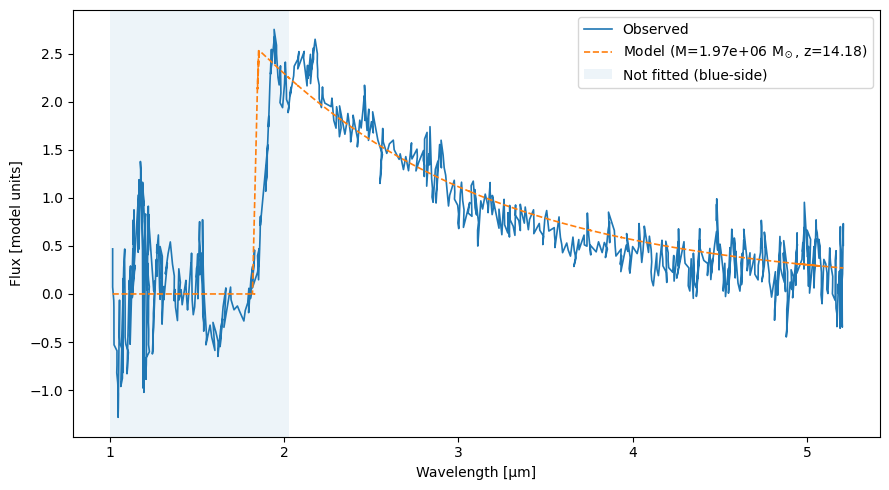

In [ ]:
from functools import partial
from scipy.optimize import minimize

# --- choose your fixed redshift ---
z_fixed = 14.18  # <- set this to whatever you want

# 1) mass-only loss with fixed z
def mse_loss_mass_only(params, lam_obs, flux_obs, z_fixed, min_wl=1.0, max_wl=5.28):
    """
    params = [log10_mass_Msun]; z is fixed externally
    """
    log10M = float(params[0])
    z = float(z_fixed)

    # Soft bound on mass
    penalty = 0.0
    if not (5.0 <= log10M <= 7.95):
        penalty += (min(0, log10M-5.0)**2 + max(0, log10M-7.95)**2) * 1e4

    mass = 10.0**log10M

    try:
        model_flux, _ = spectrum_from_mass_z(
            mass_solar=mass,
            z=z,
            obs_lambda=lam_obs,
            min_wavelength=min_wl,
            max_wavelength=max_wl
        )
    except Exception:
        return 1e50

    # Red-side mask (note: keep consistent with plotting below)
    lya_um = 0.1216 * (1.0 + z)
    mask = lam_obs >= (1.1 * lya_um)
    if not np.any(mask):
        return 1e50

    resid = model_flux[mask] - flux_obs[mask]
    return np.mean(resid * resid) + penalty

# 2) run Nelder–Mead on mass only
x0_mass = np.array([6.20])  # log10(M/Msun) initial guess
res = minimize(
    fun=partial(mse_loss_mass_only, lam_obs=obs_lambda, flux_obs=obs_flux, z_fixed=z_fixed),
    x0=x0_mass,
    method="Nelder-Mead",
    options=dict(maxiter=3000, xatol=1e-4, fatol=1e-4, disp=True)
)

best_log10M = res.x[0]
best_mass = 10**best_log10M
best_z = z_fixed

print("\n=== Fit result (Nelder–Mead, mass only; z fixed) ===")
print(f"log10(M/Msun): {best_log10M:.4f}")
print(f"M/Msun       : {best_mass:.3e}")
print(f"z (fixed)    : {best_z:.4f}")
print(f"MSE          : {res.fun:.6g}")
print(f"Success?     : {res.success}, message: {res.message}")

# 3) best-fit model & plot
best_spec, _ = spectrum_from_mass_z(
    mass_solar=best_mass,
    z=best_z,
    obs_lambda=obs_lambda,
    min_wavelength=1.0,
    max_wavelength=5.28
)

plt.figure(figsize=(9,5))
plt.plot(obs_lambda, obs_flux, lw=1.2, label="Observed")
plt.plot(obs_lambda, best_spec, lw=1.2, linestyle="--",
         label=f"Model (M={best_mass:.2e} M$_\\odot$, z={best_z:.2f})")

# shade the blue-side region using the same mask rule as in the loss
lya_edge_plot = 1.1 * 0.1216 * (1.0 + best_z)
plt.axvspan(1.0, min(lya_edge_plot, obs_lambda.max()), alpha=0.08, label="Not fitted (blue-side)")

plt.xlabel("Wavelength [µm]")
plt.ylabel("Flux [model units]")
plt.legend()
plt.tight_layout()
plt.show()


####GALAXY + SMDS

In [ ]:
from functools import partial
from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------
# Config
# ------------------------------
z_fixed = 14.18     # <-- your fixed redshift
lya_buffer = 1.10   # 10% buffer for safety on the red side

# If your galaxy model needs *1e21 to match obs units (your comment says so),
# keep this as 1e21. If you already converted elsewhere, set to 1.0.
GALAXY_UNIT_SCALE = 1e21

# If your SMDS spectrum_from_mass_z already returns in the SAME units as obs,
# keep this 1.0. If you later discover a constant offset, you can change it.
SMDS_UNIT_SCALE = 1.0

# Reasonable DS mass bounds (log10)
LOGM_DS_MIN, LOGM_DS_MAX = 5.0, 8.5   # 1e5–3e8 Msun (tune as you like)

# ------------------------------
# Helpers (reuse your vector<->dict pattern)
# ------------------------------
def _params_to_vector(params, fit_keys, log_keys=()):
    x = []
    for k in fit_keys:
        v = float(params[k])
        x.append(np.log10(v) if (k in log_keys) else v)
    return np.array(x, dtype=float)

def _vector_to_params(x, base_params, fit_keys, log_keys=()):
    p = dict(base_params)
    for k, v in zip(fit_keys, x):
        p[k] = float(10.0**v) if (k in log_keys) else float(v)
    return p

# ------------------------------
# Forward models
# ------------------------------
def galaxy_flux_on_grid(lam_um, gal_params, **interp_kwargs):
    """
    Returns galaxy model flux on lam_um, scaled to match obs units.
    Uses your model_flux_at_obs_lambda() and multiplies by GALAXY_UNIT_SCALE.
    """
    gflux = model_flux_at_obs_lambda(lam_um, gal_params, **interp_kwargs)
    return np.asarray(gflux) * GALAXY_UNIT_SCALE

def smds_flux_on_grid(lam_um, log10M_DS, z, **smds_kwargs):
    """
    Returns SMDS model flux on lam_um. Mass is 10**log10M_DS [Msun].
    Uses your spectrum_from_mass_z(); scaled by SMDS_UNIT_SCALE if needed.
    """
    M_sun = 10.0**float(log10M_DS)
    sflux, _meta = spectrum_from_mass_z(
        mass_solar=M_sun, z=z, obs_lambda=lam_um,
        min_wavelength=smds_kwargs.get("min_wavelength", 1.0),
        max_wavelength=smds_kwargs.get("max_wavelength", 5.28),
    )
    return np.asarray(sflux) * SMDS_UNIT_SCALE

# ------------------------------
# Objective: joint galaxy + SMDS
# ------------------------------
def mse_joint_galaxy_smds(
    x,
    obs_lambda_um,
    obs_flux,
    base_gal_params,
    gal_fit_keys=("logM","age","tau","Z","Av"),
    gal_log_keys=("age","tau","Z"),
    z_fixed=14.18,
    lya_buffer=1.10,
    fit_mask=None,
    # galaxy model kwargs
    R=1000, apply_igm=True, lya_cap_factor=1.0, lya_window_kms=600.0, veldisp_kms=80.0,
    kind="linear", fill_value=0.0,
    # SMDS kwargs
    smds_min_wl=1.0, smds_max_wl=5.28,
):
    """
    x packs: [galaxy_params..., logM_DS]
    Galaxy params mapped via (gal_fit_keys, gal_log_keys) using base_gal_params as template.
    The last element is logM_DS (always optimized in linear space here).
    """
    gal_log_keys = set(gal_log_keys)

    # Split vector: galaxy part + DS logM
    x_gal = x[:-1]
    log10M_DS = float(x[-1])

    # Penalties (keep NM unconstrained but sane)
    penalty = 0.0
    if not (LOGM_DS_MIN <= log10M_DS <= LOGM_DS_MAX):
        # quadratic wall
        if log10M_DS < LOGM_DS_MIN:
            penalty += (LOGM_DS_MIN - log10M_DS)**2 * 1e4
        if log10M_DS > LOGM_DS_MAX:
            penalty += (log10M_DS - LOGM_DS_MAX)**2 * 1e4

    # Build galaxy param dict from vector; enforce fixed z
    gal_params = _vector_to_params(x_gal, base_gal_params, gal_fit_keys, log_keys=gal_log_keys)
    gal_params["z"] = float(z_fixed)

    # Compute models
    try:
        gal_flux = galaxy_flux_on_grid(
            obs_lambda_um, gal_params,
            R=R, apply_igm=apply_igm, lya_cap_factor=lya_cap_factor,
            lya_window_kms=lya_window_kms, veldisp_kms=veldisp_kms,
            kind=kind, fill_value=fill_value
        )
        ds_flux = smds_flux_on_grid(
            obs_lambda_um, log10M_DS, z_fixed,
            min_wavelength=smds_min_wl, max_wavelength=smds_max_wl
        )
    except Exception:
        return 1e50  # fail-safe

    total_flux = gal_flux + ds_flux

    # Mask: red side only
    if fit_mask is None:
        lya_um = 0.1216 * (1.0 + z_fixed)
        mask = obs_lambda_um >= (lya_buffer * lya_um)
    else:
        mask = np.asarray(fit_mask, dtype=bool)

    if not np.any(mask):
        return 1e50

    r = total_flux[mask] - obs_flux[mask]
    return float(np.mean(r*r) + penalty)

# ------------------------------
# Driver: joint fit
# ------------------------------
def fit_joint_galaxy_plus_smds(
    obs_lambda_um, obs_flux,
    base_gal_params,
    gal_fit_keys=("logM","age","tau","Z","Av"),
    gal_log_keys=("age","tau","Z"),
    x0_gal=None, x0_logM_DS=6.0,
    z_fixed=14.18, lya_buffer=1.10,
    fit_mask=None,
    nm_options=None,
    # galaxy/SMDS kwargs
    R=1000, apply_igm=True, lya_cap_factor=1.0, lya_window_kms=600.0, veldisp_kms=80.0,
    kind="linear", fill_value=0.0,
    smds_min_wl=1.0, smds_max_wl=5.28,
):
    if isinstance(gal_fit_keys, str):
        gal_fit_keys = (gal_fit_keys,)
    else:
        gal_fit_keys = tuple(gal_fit_keys)

    gal_log_keys = set(gal_log_keys)

    # Build starting vector
    if x0_gal is None:
        x0_gal = _params_to_vector(base_gal_params, gal_fit_keys, log_keys=gal_log_keys)
    x0 = np.concatenate([x0_gal, np.atleast_1d(x0_logM_DS)])

    # Objective partial
    obj = partial(
        mse_joint_galaxy_smds,
        obs_lambda_um=obs_lambda_um,
        obs_flux=obs_flux,
        base_gal_params=base_gal_params,
        gal_fit_keys=gal_fit_keys,
        gal_log_keys=gal_log_keys,
        z_fixed=z_fixed,
        lya_buffer=lya_buffer,
        fit_mask=fit_mask,
        R=R, apply_igm=apply_igm, lya_cap_factor=lya_cap_factor,
        lya_window_kms=lya_window_kms, veldisp_kms=veldisp_kms,
        kind=kind, fill_value=fill_value,
        smds_min_wl=smds_min_wl, smds_max_wl=smds_max_wl,
    )

    res = minimize(
        obj, x0, method="Nelder-Mead",
        options={"maxiter": 200, "xatol": 1e-4, "fatol": 1e-6, **(nm_options or {})}
    )

    # Unpack best
    x_best = res.x
    gal_best = _vector_to_params(x_best[:-1], base_gal_params, gal_fit_keys, log_keys=gal_log_keys)
    gal_best["z"] = float(z_fixed)
    log10M_DS_best = float(x_best[-1])

    # Recompute full best-fit spectra
    gal_best_flux = galaxy_flux_on_grid(
        obs_lambda_um, gal_best,
        R=R, apply_igm=apply_igm, lya_cap_factor=lya_cap_factor,
        lya_window_kms=lya_window_kms, veldisp_kms=veldisp_kms,
        kind=kind, fill_value=fill_value
    )
    ds_best_flux = smds_flux_on_grid(
        obs_lambda_um, log10M_DS_best, z_fixed,
        min_wavelength=smds_min_wl, max_wavelength=smds_max_wl
    )
    total_best_flux = gal_best_flux + ds_best_flux

    return {
        "result": res,
        "best_galaxy_params": gal_best,
        "best_log10M_DS": log10M_DS_best,
        "galaxy_flux_best": gal_best_flux,
        "smds_flux_best": ds_best_flux,
        "total_flux_best": total_best_flux,
        "fit_mask": fit_mask,
    }



Converged: False Maximum number of iterations has been exceeded.
Best galaxy params: {'z': 14.18, 'logM': 8.394519417657133, 'age': 0.031218446516146928, 'tau': 0.011891589417621735, 'Z': 0.008336738000805963, 'Av': 0.15415878898202928, 'logU': -3.06050912419715, 'fesc': 0.1375830734118516}
Best log10(M_DS/Msun): 5.9375271268876855
Best MSE: 0.0379752738173202


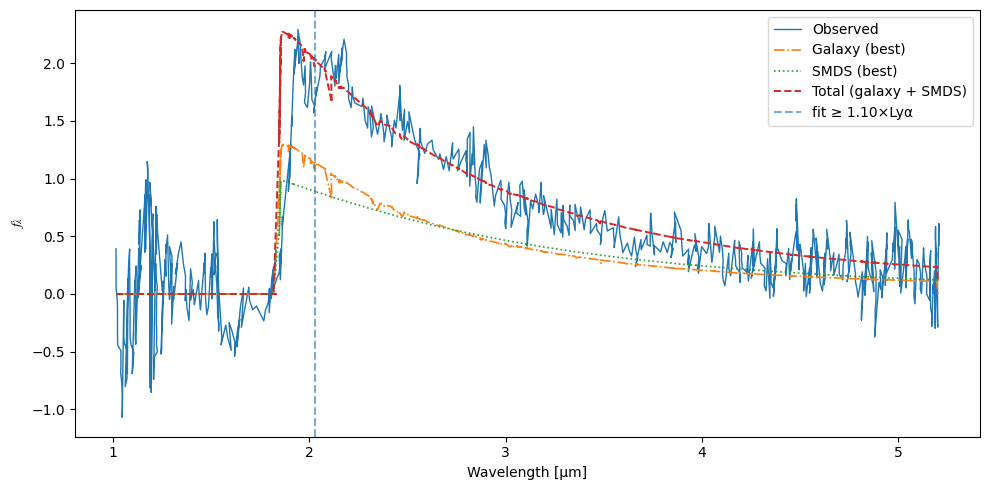

In [ ]:
# ------------------------------
# Example usage
# ------------------------------
# Observed (you already loaded these)
# obs_lambda = ...   # µm
# obs_flux   = ...   # same units as galaxy_flux_on_grid & smds_flux_on_grid sum
# Observed
df = pd.read_csv("JZ14_spec.csv")
obs_lambda = np.array(df["Wavelength"])      # µm
obs_flux   = np.array(df[" Flux"])/1.2           # keep as-is (model *1e21 inside _mse)

# Base galaxy & which params to fit
base_gal = {"z": z_fixed, "logM": 7.8, "age": 0.03, "tau": 0.03, "Z": 0.01, "Av": 0.15,
            "logU": -2.5, "fesc": 0.7}

fit_keys_gal = ("logM", "age", "tau", "Z", "Av", "logU", "fesc")
log_keys_gal = ("age", "tau", "Z")

# Red-side-only mask (same rule as objective if you prefer explicit)
lya_um = 0.1216 * (1.0 + z_fixed)
lam_min_fit = lya_buffer * lya_um
fit_mask = (obs_lambda >= lam_min_fit)

out = fit_joint_galaxy_plus_smds(
    obs_lambda, obs_flux,
    base_gal_params=base_gal,
    gal_fit_keys=fit_keys_gal, gal_log_keys=log_keys_gal,
    x0_logM_DS=6.0,  # initial guess for SMDS log10(M/Msun)
    z_fixed=z_fixed, lya_buffer=lya_buffer,
    fit_mask=fit_mask,
    R=1000, apply_igm=True, lya_cap_factor=1.0,
    lya_window_kms=600.0, veldisp_kms=80.0
)

print("Converged:", out["result"].success, out["result"].message)
print("Best galaxy params:", out["best_galaxy_params"])
print("Best log10(M_DS/Msun):", out["best_log10M_DS"])
print("Best MSE:", out["result"].fun)

# Plot: components + total
plt.figure(figsize=(10,5))
plt.plot(obs_lambda, obs_flux, lw=1.0, label="Observed")
plt.plot(obs_lambda, out["galaxy_flux_best"], lw=1.2, ls="-.", label="Galaxy (best)")
plt.plot(obs_lambda, out["smds_flux_best"], lw=1.2, ls=":", label="SMDS (best)")
plt.plot(obs_lambda, out["total_flux_best"], lw=1.4, ls="--", label="Total (galaxy + SMDS)")
plt.axvline(lam_min_fit, ls="--", alpha=0.6, label=f"fit ≥ {lya_buffer:.2f}×Lyα")
plt.axvline(0.1640*(1+14.18), ls="--", alpha=0.6, label=f"He1640")
plt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\lambda$")
plt.legend(); plt.tight_layout(); plt.show()


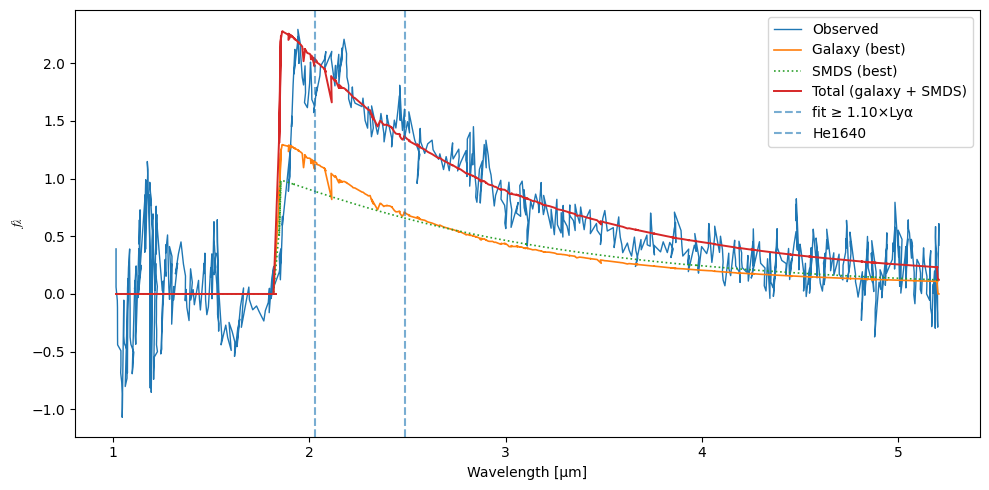

In [ ]:
# Plot: components + total
plt.figure(figsize=(10,5))
plt.plot(obs_lambda, obs_flux, lw=1.0, label="Observed")
plt.plot(obs_lambda, out["galaxy_flux_best"], lw=1.2,  label="Galaxy (best)")
plt.plot(obs_lambda, out["smds_flux_best"], lw=1.2, ls=":", label="SMDS (best)")
plt.plot(obs_lambda, out["total_flux_best"], lw=1.4, label="Total (galaxy + SMDS)")
plt.axvline(lam_min_fit, ls="--", alpha=0.6, label=f"fit ≥ {lya_buffer:.2f}×Lyα")
plt.axvline(0.1640*(1+14.18), ls="--", alpha=0.6, label=f"He1640")
plt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\lambda$")
plt.legend(); plt.tight_layout(); plt.show()


In [ ]:
import numpy as np

def sfr_exp_tau(logM, age_gyr, tau_gyr):
    """
    Exponentially declining SFH: SFR(t) ∝ exp(-t/τ)
    Current SFR at t=age (M⊙/yr) given:
      logM   = log10(total formed stellar mass in M⊙)
      age_gyr, tau_gyr in Gyr
    Formula:
      SFR(age) = M * exp(-a) / [ τ * (1 - exp(-a)) ]    [M⊙/Gyr]
      (divide by 1e9 to get M⊙/yr), where a = age/τ
    """
    M = 10.0**np.asarray(logM, dtype=float)
    age = np.asarray(age_gyr, dtype=float)
    tau = np.asarray(tau_gyr, dtype=float)

    a = age / tau
    # Use expm1 for stability: 1 - exp(-a) = -expm1(-a)
    denom = tau * (-np.expm1(-a))              # [Gyr]
    numer = M * np.exp(-a)                     # [M⊙]
    sfr_gyr = numer / denom                    # [M⊙/Gyr]
    return sfr_gyr / 1e9                       # [M⊙/yr]


def sfr_delayed_tau(logM, age_gyr, tau_gyr):
    """
    Delayed-τ SFH: SFR(t) ∝ t * exp(-t/τ)
    Current SFR at t=age (M⊙/yr) given:
      logM   = log10(total formed stellar mass in M⊙)
      age_gyr, tau_gyr in Gyr
    Formula (normalized so ∫ SFR dt = M over [0, age]):
      SFR(age) = M * (age/τ^2) * exp(-a) / [1 - (1 + a) * exp(-a)]  [M⊙/Gyr]
      with a = age/τ
    """
    M = 10.0**np.asarray(logM, dtype=float)
    age = np.asarray(age_gyr, dtype=float)
    tau = np.asarray(tau_gyr, dtype=float)

    a = age / tau
    ea = np.exp(-a)
    denom = 1.0 - (1.0 + a) * ea               # dimensionless
    numer = M * (age / (tau**2)) * ea          # [M⊙/Gyr]
    sfr_gyr = numer / denom                    # [M⊙/Gyr]
    return sfr_gyr / 1e9                       # [M⊙/yr]


def compute_sfr_from_best(best_params, sfh="exp"):
    """
    Convenience wrapper: pass your optimizer output dict (with 'logM','age','tau').
    sfh: 'exp' for exponentially declining, 'delayed' for delayed-τ.
    Returns SFR in M⊙/yr (float or ndarray).
    """
    logM = best_params["logM"]
    age  = best_params["age"]   # Gyr
    tau  = best_params["tau"]   # Gyr

    if sfh.lower().startswith("exp"):
        return sfr_exp_tau(logM, age, tau)
    elif sfh.lower().startswith("del"):
        return sfr_delayed_tau(logM, age, tau)
    else:
        raise ValueError("sfh must be 'exp' or 'delayed'.")

# -------------------------
# Example with your numbers
# -------------------------
best_params = {'z': 14.18, 'logM': 8.39,
               'age': 0.03, 'tau': 0.01}

sfr_exp = compute_sfr_from_best(best_params, sfh="exp")
sfr_del = compute_sfr_from_best(best_params, sfh="delayed")

print(f"SFR (exp-τ):     {sfr_exp:.3f} Msun/yr")
print(f"SFR (delayed-τ): {sfr_del:.3f} Msun/yr")


SFR (exp-τ):     1.286 Msun/yr
SFR (delayed-τ): 4.578 Msun/yr


Converged: False Maximum number of iterations has been exceeded.
Best galaxy params: {'z': 13.9, 'logM': 8.305249370620917, 'age': 0.052523892365167295, 'tau': 0.010639021519268231, 'Z': 0.00642121782252206, 'Av': 0.13695992734978113, 'logU': -1.9639929332454331, 'fesc': 0.7483457449416009}
Best log10(M_DS/Msun): 5.212765007325876
Best MSE: 0.014843815916733952


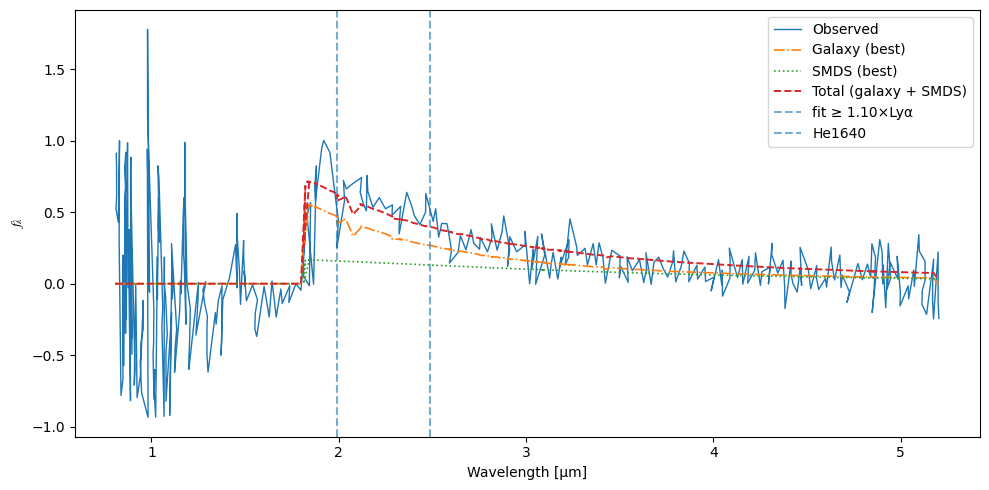

In [ ]:
# ------------------------------
# Example usage
# ------------------------------
# Observed (you already loaded these)
# obs_lambda = ...   # µm
# obs_flux   = ...   # same units as galaxy_flux_on_grid & smds_flux_on_grid sum
# Observed
df = pd.read_csv("JZ_14_1.csv")
obs_lambda = np.array(df["Wavelength"])      # µm
obs_flux   = np.array(df[" Flux"])           # keep as-is (model *1e21 inside _mse)
z_fixed = 13.9
# Base galaxy & which params to fit
base_gal = {"z": z_fixed, "logM": 7.8, "age": 0.03, "tau": 0.03, "Z": 0.01, "Av": 0.15,
            "logU": -2.5, "fesc": 0.7}

fit_keys_gal = ("logM", "age", "tau", "Z", "Av", "logU", "fesc")
log_keys_gal = ("age", "tau", "Z")

# Red-side-only mask (same rule as objective if you prefer explicit)
lya_um = 0.1216 * (1.0 + z_fixed)
lam_min_fit = lya_buffer * lya_um
fit_mask = (obs_lambda >= lam_min_fit)

out = fit_joint_galaxy_plus_smds(
    obs_lambda, obs_flux,
    base_gal_params=base_gal,
    gal_fit_keys=fit_keys_gal, gal_log_keys=log_keys_gal,
    x0_logM_DS=6.0,  # initial guess for SMDS log10(M/Msun)
    z_fixed=z_fixed, lya_buffer=lya_buffer,
    fit_mask=fit_mask,
    R=1000, apply_igm=True, lya_cap_factor=1.0,
    lya_window_kms=600.0, veldisp_kms=80.0
)

print("Converged:", out["result"].success, out["result"].message)
print("Best galaxy params:", out["best_galaxy_params"])
print("Best log10(M_DS/Msun):", out["best_log10M_DS"])
print("Best MSE:", out["result"].fun)

# Plot: components + total
plt.figure(figsize=(10,5))
plt.plot(obs_lambda, obs_flux, lw=1.0, label="Observed")
plt.plot(obs_lambda, out["galaxy_flux_best"], lw=1.2, ls="-.", label="Galaxy (best)")
plt.plot(obs_lambda, out["smds_flux_best"], lw=1.2, ls=":", label="SMDS (best)")
plt.plot(obs_lambda, out["total_flux_best"], lw=1.4, ls="--", label="Total (galaxy + SMDS)")
plt.axvline(lam_min_fit, ls="--", alpha=0.6, label=f"fit ≥ {lya_buffer:.2f}×Lyα")
plt.axvline(0.1640*(1+14.18), ls="--", alpha=0.6, label=f"He1640")
plt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\lambda$")
plt.legend(); plt.tight_layout(); plt.show()


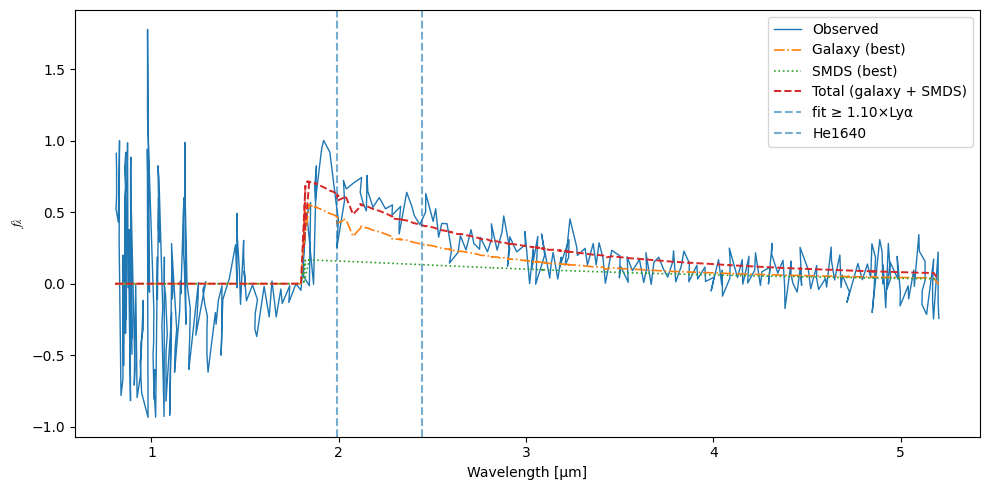

In [ ]:
# Plot: components + total
plt.figure(figsize=(10,5))
plt.plot(obs_lambda, obs_flux, lw=1.0, label="Observed")
plt.plot(obs_lambda, out["galaxy_flux_best"], lw=1.2, ls="-.", label="Galaxy (best)")
plt.plot(obs_lambda, out["smds_flux_best"], lw=1.2, ls=":", label="SMDS (best)")
plt.plot(obs_lambda, out["total_flux_best"], lw=1.4, ls="--", label="Total (galaxy + SMDS)")
plt.axvline(lam_min_fit, ls="--", alpha=0.6, label=f"fit ≥ {lya_buffer:.2f}×Lyα")
plt.axvline(0.1640*(1+13.9), ls="--", alpha=0.6, label=f"He1640")
plt.xlabel("Wavelength [µm]"); plt.ylabel(r"$f_\lambda$")
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
best_params = {'z': 13.9, 'logM': 8.3,
               'age': 0.05, 'tau': 0.01}

sfr_exp = compute_sfr_from_best(best_params, sfh="exp")
sfr_del = compute_sfr_from_best(best_params, sfh="delayed")

print(f"SFR (exp-τ):     {sfr_exp:.3f} Msun/yr")
print(f"SFR (delayed-τ): {sfr_del:.3f} Msun/yr")

SFR (exp-τ):     0.135 Msun/yr
SFR (delayed-τ): 0.701 Msun/yr


######RANDOM

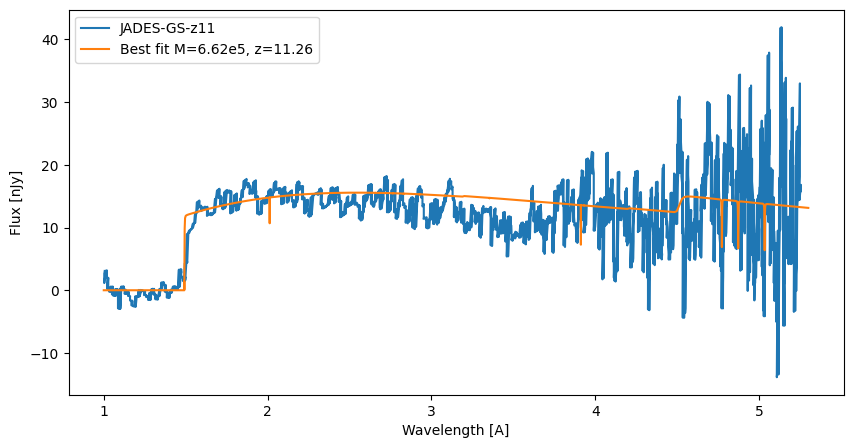

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import minimize
from functools import partial
def ergs_per_cm2_per_A_to_nanojansky(F_lambda_A, wavelength_micron):
    """
    Convert monochromatic flux density from F_lambda (erg s^-1 cm^-2 Å^-1)
    at a given wavelength (in microns) to nanoJansky (nJy), step by step.

    Uses: F_nu = F_lambda * lambda^2 / c
    with F_lambda expressed per centimeter (not per Å), and lambda in cm.
    """
    # --- Physical constants ---
    c_cm_per_s = 2.99792458e10     # speed of light [cm/s]
    ANGSTROM_PER_CM = 1e8          # 1 cm = 1e8 Å
    JY_IN_CGS = 1e-23              # 1 Jy = 1e-23 erg s^-1 cm^-2 Hz^-1
    NJY_PER_JY = 1e9               # 1 Jy = 1e9 nJy

    # --- Wavelength conversions ---
    # input wavelength in microns -> centimeters (1 micron = 1e-4 cm)
    lam_cm = wavelength_micron * 1e-4

    # --- Convert F_lambda from per Å to per cm ---
    # F_lambda [erg s^-1 cm^-2 Å^-1] -> [erg s^-1 cm^-2 cm^-1]
    F_lambda_per_cm = F_lambda_A * ANGSTROM_PER_CM

    # --- Convert from per wavelength to per frequency ---
    # F_nu [erg s^-1 cm^-2 Hz^-1] = F_lambda [erg s^-1 cm^-2 cm^-1] * (lambda^2 / c)
    F_nu_cgs = F_lambda_per_cm * (lam_cm ** 2) / c_cm_per_s

    # --- Convert to Janskys ---
    F_nu_Jy = F_nu_cgs / JY_IN_CGS

    # --- Convert to nanoJanskys ---
    F_nu_nJy = F_nu_Jy * NJY_PER_JY

    return F_nu_nJy

import pandas as pd
df = pd.read_csv("JZ11_spec.csv")
flux_A = np.array(df[' Flux'])*1e-21
lambda_A = np.array(df['Wavelength'])
flux_nJy = ergs_per_cm2_per_A_to_nanojansky(flux_A, lambda_A)


obs_lambda = np.linspace(1.0, 5.3, 40000)   # microns
spec, info = spectrum_from_mass_z(6.62e5, 11.26, obs_lambda)
spec = spec * 1e-21

spec_njy = ergs_per_cm2_per_A_to_nanojansky(spec, obs_lambda)

plt.figure(figsize=(10,5))
plt.plot(lambda_A, flux_nJy, label="JADES-GS-z11")
plt.plot(obs_lambda, spec_njy, label="Best fit M=6.62e5, z=11.26")
plt.xlabel('Wavelength [A]')
plt.ylabel('Flux [nJy]')
plt.legend()
plt.show()
